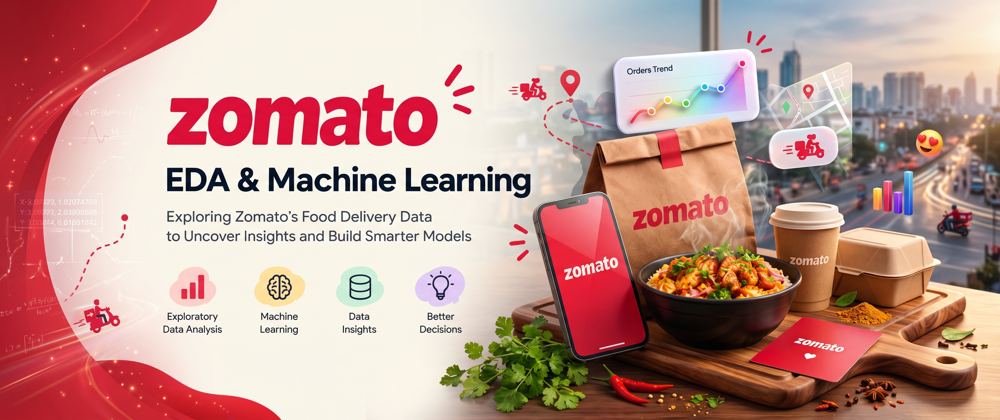

# 🍽️ Zomato Restaurant Data Analysis & Rating Prediction

## Table of Contents
1. [Introduction](#introduction)
2. [Data Understanding and Cleaning](#data-cleaning)
    - [2.1 Setup and Data Loading](#loading) · [2.2 Initial Inspection](#inspection) · [2.3 Address](#address) · [2.4 Online Ordering and Table Booking](#online-booking) · [2.5 Rating Cleaning](#rating-cleaning) · [2.6 Votes](#votes) · [2.7 Location](#location-cleaning) · [2.8 Rating Imputation](#rating-imputation) · [2.9 Feature Engineering](#feature-engineering)
3. [Exploratory Data Analysis](#eda)
    - [3.1 Business Question](#business-question) · [3.2 Restaurant Types and Dishes](#types-dishes) · [3.3 Restaurant Performance](#performance) · [3.4 Location Analysis](#location-analysis) · [3.5 Cuisine Analysis](#cuisine-analysis) · [3.6 Customer Preferences](#customer-preferences) · [3.7 Pricing Analysis](#pricing-analysis) · [3.8 Ratings and Market Comparison](#ratings-market)
4. [Feature Encoding](#encoding)
5. [Machine Learning Modelling](#modelling)
    - [5.1 Approach](#approach) · [5.2 Single-Feature Screening](#screening) · [5.3 Baseline Models](#baseline) · [5.4 Group-Aware Validation](#group-split) · [5.5 Improving Generalization](#generalization) · [5.6 Regression Model Comparison](#regression) · [5.7 Classification Models](#classification)
6. [Conclusion](#conclusion)

<a id="introduction"></a>
## 1. Introduction

The restaurant industry is highly competitive, so understanding customer preferences and restaurant performance is valuable. This project analyses the Zomato Bangalore restaurant dataset to find patterns, identify what is associated with ratings, and predict restaurant ratings.

**Objectives:** clean the data, explore it through visualisations, engineer and encode features, and build and evaluate regression and classification models.
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn and Scikit-learn.
**Workflow:** data cleaning → EDA → feature encoding → modelling → conclusions.

<a id="data-cleaning"></a>
## 2. Data Understanding and Cleaning

This section inspects the structure and quality of the raw data and prepares clean columns for analysis.

<a id="loading"></a>
### 2.1 Setup and Data Loading

Import the required libraries.

In [366]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

import re
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

Load the dataset and keep a copy of the raw data.

In [367]:
df2 = pd.read_csv('zomato.csv')

<a id="inspection"></a>
### 2.2 Initial Inspection

Check the structure, summary statistics, missing values and duplicates. The raw data has 51,717 rows and 17 columns, with no duplicate rows.

In [368]:
df = df2.copy()
df.head()

,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
0,https://www.zomato.com/bangalore/jalsa-banasha...,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1/5,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari
1,https://www.zomato.com/bangalore/spice-elephan...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1/5,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari
2,https://www.zomato.com/SanchurroBangalore?cont...,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8/5,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari
3,https://www.zomato.com/bangalore/addhuri-udupi...,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7/5,88,+91 9620009302,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300,"[('Rated 4.0', ""RATED\n Great food and proper...",[],Buffet,Banashankari
4,https://www.zomato.com/bangalore/grand-village...,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8/5,166,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600,"[('Rated 4.0', 'RATED\n Very good restaurant ...",[],Buffet,Banashankari


In [369]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51717 entries, 0 to 51716
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   url                          51717 non-null  str  
 1   address                      51717 non-null  str  
 2   name                         51717 non-null  str  
 3   online_order                 51717 non-null  str  
 4   book_table                   51717 non-null  str  
 5   rate                         43942 non-null  str  
 6   votes                        51717 non-null  int64
 7   phone                        50509 non-null  str  
 8   location                     51696 non-null  str  
 9   rest_type                    51490 non-null  str  
 10  dish_liked                   23639 non-null  str  
 11  cuisines                     51672 non-null  str  
 12  approx_cost(for two people)  51371 non-null  str  
 13  reviews_list                 51717 non-null  str  
 14  m

In [370]:
df.describe()

,votes
count,51717.000000
mean,283.697527
std,803.838853
min,0.000000
25%,7.000000
50%,41.000000
75%,198.000000
max,16832.000000


In [371]:
df.isna().sum()

url                                0
address                            0
name                               0
online_order                       0
book_table                         0
rate                            7775
votes                              0
phone                           1208
location                          21
rest_type                        227
dish_liked                     28078
cuisines                          45
approx_cost(for two people)      346
reviews_list                       0
menu_item                          0
listed_in(type)                    0
listed_in(city)                    0
dtype: int64

In [372]:
df.duplicated().sum()

np.int64(0)

In [373]:
len(df['name'].unique())

8792

Check whether all URLs follow the same pattern.

In [374]:
df[df['url'].str.contains('https://www.zomato.com/bangalore') == False].head()

,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
2,https://www.zomato.com/SanchurroBangalore?cont...,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8/5,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari
14,https://www.zomato.com/SanchurroBangalore?cont...,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8/5,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Cafes,Banashankari
67,https://www.zomato.com/gustoesbeerhouse?contex...,"10, 30th Main, Deve Gowda Petrol Bunk Road, 3r...",Gustoes Beer House,No,No,4.1/5,868,080 49653521,Banashankari,Pub,"Beer, Wedges, Pizza, Nachos, Salads, Papaya Sa...","Continental, Italian, Mexican, North Indian, C...","1,200","[('Rated 5.0', 'RATED\n Has a really calm roo...",[],Delivery,Banashankari
296,https://www.zomato.com/rusticstove?context=eyJ...,"13, 32nd Cross, 7th Block, Jayanagar, Bangalore",Rustic Stove,Yes,No,3.8/5,577,080 26547755\r\n+91 9686372742,Jayanagar,Casual Dining,"Vegetable Biryani, Pineapple Rasam, Cheese Gar...","North Indian, South Indian, Biryani, Beverages",900,"[('Rated 1.0', 'RATED\n Had been for dinner l...",[],Delivery,Banashankari
355,https://www.zomato.com/as-on-fire-food-truck?c...,"75, 21st Main Road, Siddanna Layout, 2nd Stage...",As On Fire,Yes,No,3.5/5,41,+91 9731111852,South Bangalore,Food Truck,Pizza,"Pizza, Fast Food, BBQ",400,"[('Rated 5.0', 'RATED\n Great place. Can go f...",[],Delivery,Banashankari


Some URLs differ from the standard pattern; the column may be used later.

<a id="address"></a>
### 2.3 Address

In [375]:
arr = df['address']

# Set the display width to a high number (e.g., 1000 characters)
#pd.set_option('display.max_colwidth', None)
# Now print your array

#(the location is at index -2 in address)
print(arr[0:7])

0    942, 21st Main Road, 2nd Stage, Banashankari, ...
1    2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...
2    1112, Next to KIMS Medical College, 17th Cross...
3    1st Floor, Annakuteera, 3rd Stage, Banashankar...
4    10, 3rd Floor, Lakshmi Associates, Gandhi Baza...
5    37, 5-1, 4th Floor, Bosco Court, Gandhi Bazaar...
6    19/1, New Timberyard Layout, Beside Satellite ...
Name: address, dtype: str


Display the full addresses so that missing `location` values can be filled from them later.

<a id="online-booking"></a>
### 2.4 Online Ordering and Table Booking

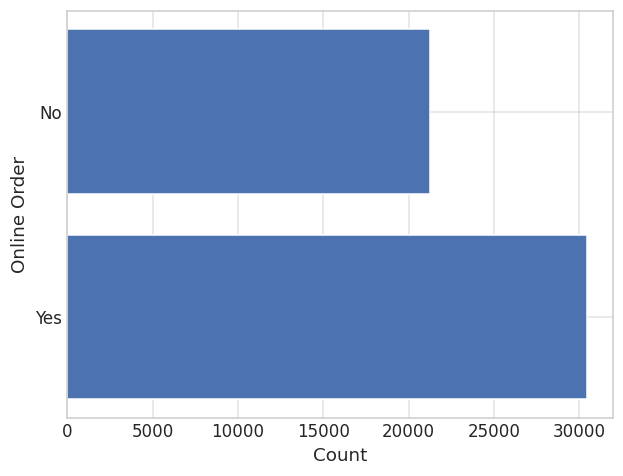

In [376]:
counts = df['online_order'].value_counts()

plt.barh(counts.index.astype(str), counts.values)
plt.xlabel('Count')
plt.ylabel('Online Order')
plt.show()

More restaurants offer online ordering (30,444) than do not (21,273).

In [377]:
print(df['online_order'].value_counts())

online_order
Yes    30444
No     21273
Name: count, dtype: int64


**Table booking**

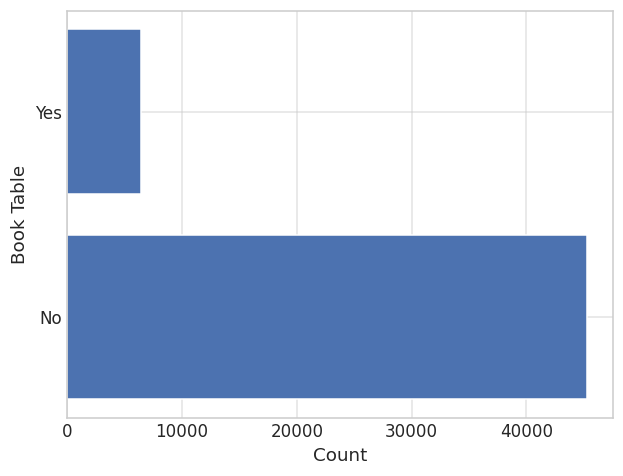

In [378]:
counts = df['book_table'].value_counts()

plt.barh(counts.index.astype(str), counts.values)
plt.xlabel('Count')
plt.ylabel('Book Table')
plt.show()

In [379]:
print(df['book_table'].value_counts())

book_table
No     45268
Yes     6449
Name: count, dtype: int64


Most restaurants do not offer table booking (45,268 vs. 6,449).

<a id="rating-cleaning"></a>
### 2.5 Rating Cleaning

`rate` is stored as text (e.g. "4.1/5") and contains "NEW" and "-" placeholders and 7,775 nulls. The steps below standardise these values and convert the column to numeric.

In [380]:
df['rate'].unique()

<StringArray>
[ '4.1/5',  '3.8/5',  '3.7/5',  '3.6/5',  '4.6/5',  '4.0/5',  '4.2/5',
  '3.9/5',  '3.1/5',  '3.0/5',  '3.2/5',  '3.3/5',  '2.8/5',  '4.4/5',
  '4.3/5',    'NEW',  '2.9/5',  '3.5/5',      nan,  '2.6/5', '3.8 /5',
  '3.4/5',  '4.5/5',  '2.5/5',  '2.7/5',  '4.7/5',  '2.4/5',  '2.2/5',
  '2.3/5', '3.4 /5',      '-', '3.6 /5',  '4.8/5', '3.9 /5', '4.2 /5',
 '4.0 /5', '4.1 /5', '3.7 /5', '3.1 /5', '2.9 /5', '3.3 /5', '2.8 /5',
 '3.5 /5', '2.7 /5', '2.5 /5', '3.2 /5', '2.6 /5', '4.5 /5', '4.3 /5',
 '4.4 /5',  '4.9/5',  '2.1/5',  '2.0/5',  '1.8/5', '4.6 /5', '4.9 /5',
 '3.0 /5', '4.8 /5', '2.3 /5', '4.7 /5', '2.4 /5', '2.1 /5', '2.2 /5',
 '2.0 /5', '1.8 /5']
Length: 65, dtype: str

In [381]:
df['rate'].isna().sum()

np.int64(7775)

In [382]:
arr = df[df['rate'] == 'NEW']
arr.shape[0]

2208

In [383]:
arr = df[df['rate'] == '-']
arr.shape[0]

69

In [384]:
arr = df[(df['rate'] == '-') & (df['reviews_list'] == '[]')]
arr.shape[0] #45
#Those 45 will go with class new
#others will be nulls

45

In [385]:
# Step 1: Find the condition
mask = (df['rate'] == '-') & (df['reviews_list'] == '[]')

# Step 2: Replace only those 45 rows with 'NEW'
df.loc[mask, 'rate'] = 'NEW'

# Verify
print(df.loc[mask, 'rate'].unique())  # Should be empty (no more '-')
print((df['rate'] == 'NEW').sum())    # Should be 45 + any existing 'NEW'

<StringArray>
['NEW']
Length: 1, dtype: str
2253


In [386]:
# Step 1: Replace 'NEW' with -1
df['rate'] = df['rate'].replace('NEW', '-1.0')  # Add .0 so regex catches it

# Step 2: Extract number (handles both '4.1' and '-1.0')
df['rate'] = df['rate'].astype(str).str.extract(r'(-?\d+\.?\d*)').astype(float)

# Check
print(df['rate'].unique())
print(df['rate'].isna().sum())
print(df[df['rate'] == -1.0].shape[0])  # Should show 45 for the rows we set to 'NEW'

[ 4.1  3.8  3.7  3.6  4.6  4.   4.2  3.9  3.1  3.   3.2  3.3  2.8  4.4
  4.3 -1.   2.9  3.5  nan  2.6  3.4  4.5  2.5  2.7  4.7  2.4  2.2  2.3
  4.8  4.9  2.1  2.   1.8]
7799
2253


Of the 69 restaurants rated "-", 45 had no reviews and were labelled NEW; the rest were set to null. NEW was then encoded as -1.0 so the column could be converted to float.

In [387]:
df['rate'] = df['rate'].drop(df[df['rate'] == -1.0].index)

Restaurants with no rating (-1.0) were set to missing, because they cannot be used as a modelling target.

<a id="votes"></a>
### 2.6 Votes

In [388]:
df[df['votes'] == 0].head()

,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
72,https://www.zomato.com/bangalore/spicy-tandoor...,"Opposite ICICi Bank, Hanuman Nagar, Banashanka...",Spicy Tandoor,No,No,NaN,0,+91 8050884222,Banashankari,Quick Bites,NaN,North Indian,150,"[('Rated 4.0', 'RATED\n cost for chicken roll...",[],Delivery,Banashankari
75,https://www.zomato.com/bangalore/om-sri-vinaya...,"39, S B M Colony, Near-Sita Circle, 1st Stage,...",Om Sri Vinayaka Chats,No,No,NaN,0,+91 8553206035,Banashankari,"Takeaway, Delivery",NaN,"Street Food, Fast Food",500,[],[],Delivery,Banashankari
84,https://www.zomato.com/bangalore/chill-out-ban...,"161/C, 6th Main, 80 Feet Road, Bhuvaneshwari N...",Chill Out,No,No,NaN,0,+91 9341215167,Banashankari,Quick Bites,NaN,"South Indian, Chinese",100,"[('Rated 4.0', 'RATED\n Good Location. Small ...",[],Delivery,Banashankari
90,https://www.zomato.com/bangalore/me-and-my-cak...,"BDA Shopping Complex, 24th Cross Road, Siddann...",Me And My Cake,No,No,NaN,0,+91 9036070410,Banashankari,Delivery,NaN,"Bakery, Desserts",500,"[('Rated 1.0', 'RATED\n Do not order anything...",[],Delivery,Banashankari
91,https://www.zomato.com/bangalore/sunsadm-banas...,"Shop 18 , 3rd cross road,Markandeya Layout, Ba...",Sunsadm,No,No,NaN,0,+91 7829290358,Banashankari,"Takeaway, Delivery",NaN,South Indian,400,[],[],Delivery,Banashankari


Restaurants with zero votes are noted here and will be handled later using the length of the review list.

<a id="location-cleaning"></a>
### 2.7 Location

21 locations are missing. They are filled from the address where possible.

In [389]:
print(df['location'].unique().tolist())

['Banashankari', 'Basavanagudi', 'Mysore Road', 'Jayanagar', 'Kumaraswamy Layout', 'Rajarajeshwari Nagar', 'Vijay Nagar', 'Uttarahalli', 'JP Nagar', 'South Bangalore', 'City Market', 'Nagarbhavi', 'Bannerghatta Road', 'BTM', 'Kanakapura Road', 'Bommanahalli', nan, 'CV Raman Nagar', 'Electronic City', 'HSR', 'Marathahalli', 'Sarjapur Road', 'Wilson Garden', 'Shanti Nagar', 'Koramangala 5th Block', 'Koramangala 8th Block', 'Richmond Road', 'Koramangala 7th Block', 'Jalahalli', 'Koramangala 4th Block', 'Bellandur', 'Whitefield', 'East Bangalore', 'Old Airport Road', 'Indiranagar', 'Koramangala 1st Block', 'Frazer Town', 'RT Nagar', 'MG Road', 'Brigade Road', 'Lavelle Road', 'Church Street', 'Ulsoor', 'Residency Road', 'Shivajinagar', 'Infantry Road', 'St. Marks Road', 'Cunningham Road', 'Race Course Road', 'Commercial Street', 'Vasanth Nagar', 'HBR Layout', 'Domlur', 'Ejipura', 'Jeevan Bhima Nagar', 'Old Madras Road', 'Malleshwaram', 'Seshadripuram', 'Kammanahalli', 'Koramangala 6th Block

In [390]:
address_reduction = df['address'].apply(lambda x: x.split(',')[-2] if isinstance(x, str) and len(x.split(',')) > 1 else np.nan)
address_reduction

0           Banashankari
1           Banashankari
2           Banashankari
3           Banashankari
4           Basavanagudi
              ...       
51712         Whitefield
51713         Whitefield
51714         Whitefield
51715     ITPL Main Road
51716     ITPL Main Road
Name: address, Length: 51717, dtype: str

In [391]:
df['alt_location'] = address_reduction
df.head(3)

,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city),alt_location
0,https://www.zomato.com/bangalore/jalsa-banasha...,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari,Banashankari
1,https://www.zomato.com/bangalore/spice-elephan...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari,Banashankari
2,https://www.zomato.com/SanchurroBangalore?cont...,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari,Banashankari


In [392]:
df["location"] = df["location"].fillna(df["alt_location"])
df.drop(columns=["alt_location"], inplace=True)  # Clean up the temporary column
df.head()

,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
0,https://www.zomato.com/bangalore/jalsa-banasha...,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari
1,https://www.zomato.com/bangalore/spice-elephan...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari
2,https://www.zomato.com/SanchurroBangalore?cont...,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8,918,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari
3,https://www.zomato.com/bangalore/addhuri-udupi...,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7,88,+91 9620009302,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300,"[('Rated 4.0', ""RATED\n Great food and proper...",[],Buffet,Banashankari
4,https://www.zomato.com/bangalore/grand-village...,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8,166,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600,"[('Rated 4.0', 'RATED\n Very good restaurant ...",[],Buffet,Banashankari


The 102 unique locations are grouped into broader city zones to reduce dimensionality.

In [393]:
print(len(df['location'].unique().tolist()))

102


In [394]:
df['location'].isna().sum()

np.int64(0)

In [395]:
from collections import Counter

location_groups = {
    "Central Bangalore": [
        "City Market", "MG Road", "Brigade Road", "Lavelle Road",
        "Church Street", "Richmond Road", "Residency Road",
        "Wilson Garden", "Shanti Nagar", "Infantry Road",
        "St. Marks Road", "Race Course Road", "Commercial Street",
        "Cunningham Road", "Vasanth Nagar", "Seshadripuram",
        "Majestic", "Langford Town", "Central Bangalore",
        "Shivajinagar", "Frazer Town"
    ],

    "South Bangalore": [
        "Banashankari", "Basavanagudi", "Jayanagar", "JP Nagar",
        "Uttarahalli", "Kumaraswamy Layout", "Bannerghatta Road",
        "Kanakapura Road", "South Bangalore"
    ],

    "South-East Bangalore": [
        "BTM", "Bommanahalli", "Electronic City", "HSR",
        "Koramangala", "Koramangala 1st Block",
        "Koramangala 2nd Block", "Koramangala 3rd Block",
        "Koramangala 4th Block", "Koramangala 5th Block",
        "Koramangala 6th Block", "Koramangala 7th Block",
        "Koramangala 8th Block", "Bellandur", "Sarjapur Road",
        "Hosur Road", "Ejipura"
    ],

    "East Bangalore": [
        "Whitefield", "East Bangalore", "Marathahalli",
        "Brookefield", "ITPL Main Road, Whitefield",
        "Varthur Main Road, Whitefield", "KR Puram",
        "CV Raman Nagar", "Old Airport Road", "Indiranagar",
        "Domlur", "Jeevan Bhima Nagar", "Old Madras Road",
        "Ulsoor", "Thippasandra", "Kaggadasapura"
    ],

    "North Bangalore": [
        "Jalahalli", "RT Nagar", "HBR Layout", "Banaswadi",
        "North Bangalore", "Nagawara", "Hennur",
        "Kalyan Nagar", "New BEL Road", "Jakkur",
        "Rammurthy Nagar", "Hebbal", "Yelahanka",
        "Sahakara Nagar", "Kammanahalli", "Sanjay Nagar",
        "Sadashiv Nagar"
    ],

    "West Bangalore": [
        "Rajajinagar", "West Bangalore", "Malleshwaram",
        "Peenya", "Yeshwantpur", "Sankey Road",
        "Basaveshwara Nagar", "Vijay Nagar", "Magadi Road",
        "Mysore Road", "Nagarbhavi", "Rajarajeshwari Nagar",
        "Kengeri"
    ]
}

# 1) Map each location to its group
location_map = {
    location: group
    for group, locations in location_groups.items()
    for location in locations
}

# 2) Clean extra spaces
df["location"] = df["location"].str.strip()

# 3) Create zones column: unmapped locations keep their original name
df["zones"] = df["location"].map(location_map).fillna(df["location"])

# 4) Show locations that were not mapped (should be empty)
unmapped = df.loc[
    df["location"].notna() & ~df["location"].isin(location_map.keys()),
    "location"
].unique()
print("Unmapped locations:", unmapped)

# 5) Group counts
print("\nLocation group counts:")
print(df["zones"].value_counts(dropna=False))

# 6) Number of groups
print("\nNumber of groups:", df["zones"].nunique())

Unmapped locations: <StringArray>
['Cholourpalya', 'Govindaraja Nagar']
Length: 2, dtype: str

Location group counts:
zones
South-East Bangalore    19830
East Bangalore           9669
Central Bangalore        8983
South Bangalore          7719
North Bangalore          3695
West Bangalore           1818
Cholourpalya                2
Govindaraja Nagar           1
Name: count, dtype: int64

Number of groups: 8


In [396]:
df = df[~df["zones"].isin(["Cholourpalya", "Govindaraja Nagar"])].copy()
# Cholourpalya and Govindaraja Nagar removed

<Axes: ylabel='zones'>

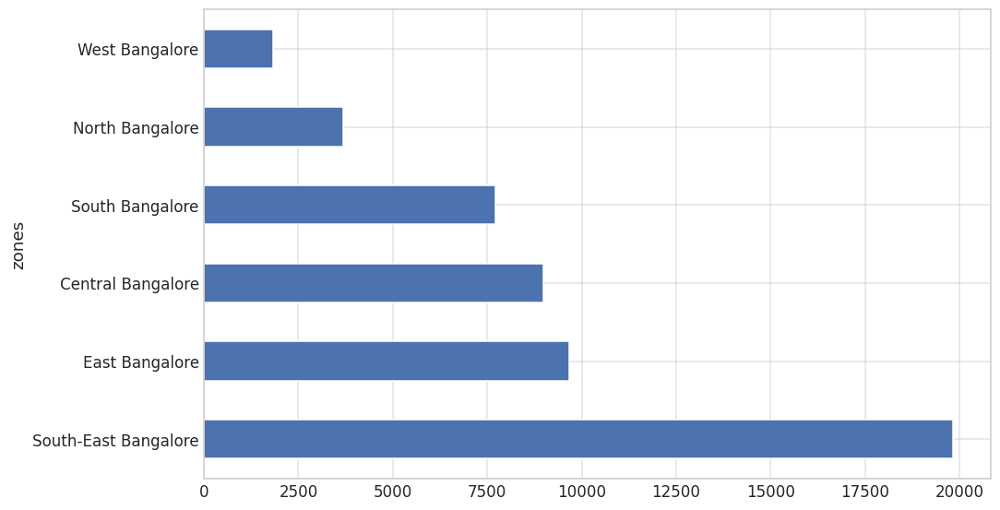

In [397]:
df['zones'].value_counts(dropna=False).plot(kind='barh', figsize=(10, 6))

<a id="rating-imputation"></a>
### 2.8 Rating Imputation

The average review score is extracted from `reviews_list` as `avg_rate`, gaps in it are filled from `rate`, and rows still missing a value are dropped.

In [398]:
# 1. Extract average review score directly into NaNs
def get_avg_rating(text):
  ratings = re.findall(r'Rated ([0-5]\.?\d?)', str(text))
  if ratings:
    mean_val = np.mean([float(r) for r in ratings])
    return min(mean_val, 5.0)  # Ensure extraction doesn't exceed 5.0
  return np.nan

# df['rate'] = df['rate'].fillna(df['reviews_list'].apply(get_avg_rating))

df['avg_rate'] = df['reviews_list'].apply(get_avg_rating)

# 2. Drop unneeded reviews column and any remaining missing targets
df = df.dropna(subset=['rate']).reset_index(drop=True)
# df = df.drop(columns=['reviews_list'], errors='ignore')

In [399]:
df['avg_rate'].agg(['min', 'max'])

min    1.0
max    5.0
Name: avg_rate, dtype: float64

In [400]:
df['avg_rate'] = df['avg_rate'].fillna(df['rate'])

In [401]:
df.isna().sum()

url                                0
address                            0
name                               0
online_order                       0
book_table                         0
rate                               0
votes                              0
phone                            814
location                           0
rest_type                        149
dish_liked                     18203
cuisines                          11
approx_cost(for two people)      247
reviews_list                       0
menu_item                          0
listed_in(type)                    0
listed_in(city)                    0
zones                              0
avg_rate                           0
dtype: int64

In [402]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41665 entries, 0 to 41664
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   url                          41665 non-null  str    
 1   address                      41665 non-null  str    
 2   name                         41665 non-null  str    
 3   online_order                 41665 non-null  str    
 4   book_table                   41665 non-null  str    
 5   rate                         41665 non-null  float64
 6   votes                        41665 non-null  int64  
 7   phone                        40851 non-null  str    
 8   location                     41665 non-null  str    
 9   rest_type                    41516 non-null  str    
 10  dish_liked                   23462 non-null  str    
 11  cuisines                     41654 non-null  str    
 12  approx_cost(for two people)  41418 non-null  str    
 13  reviews_list               

In [403]:
df = df.dropna(subset=['avg_rate']).reset_index(drop=True)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41665 entries, 0 to 41664
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   url                          41665 non-null  str    
 1   address                      41665 non-null  str    
 2   name                         41665 non-null  str    
 3   online_order                 41665 non-null  str    
 4   book_table                   41665 non-null  str    
 5   rate                         41665 non-null  float64
 6   votes                        41665 non-null  int64  
 7   phone                        40851 non-null  str    
 8   location                     41665 non-null  str    
 9   rest_type                    41516 non-null  str    
 10  dish_liked                   23462 non-null  str    
 11  cuisines                     41654 non-null  str    
 12  approx_cost(for two people)  41418 non-null  str    
 13  reviews_list               

<a id="feature-engineering"></a>
### 2.9 Feature Engineering

Create dish-based features (`dish_liked_count`, `dish_liked_score`), clean the cost column, and extract the number of cuisines per restaurant.

In [404]:
# Fill missing dish_liked values with empty string
df['dish_liked'] = df['dish_liked'].fillna('')

# Feature: Count of liked dishes per restaurant
df['dish_liked_count'] = df['dish_liked'].apply(
    lambda x: len([dish.strip() for dish in x.split(',') if dish.strip()]) if x else 0
)

dish_mean_rate = (
    df[['dish_liked', 'rate']]
    .explode('dish_liked')
    .assign(dish_liked=lambda x: x['dish_liked'].str.strip())
    .groupby('dish_liked')['rate']
    .mean()
)

df['dish_liked_score'] = 0


def calculate_dish_score(dishes):
    if not isinstance(dishes, list):
        return 0

    return sum(
        1 for dish in dishes
        if dish.strip() in dish_mean_rate.index
        and dish_mean_rate[dish.strip()] >= 4.0
    )


df['dish_liked_score'] = df['dish_liked'].apply(calculate_dish_score)

In [405]:
df.head()

,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,...,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city),zones,avg_rate,dish_liked_count,dish_liked_score
0,https://www.zomato.com/bangalore/jalsa-banasha...,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,...,"North Indian, Mughlai, Chinese",800,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari,South Bangalore,4.083333,7,0
1,https://www.zomato.com/bangalore/spice-elephan...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1,787,080 41714161,Banashankari,Casual Dining,...,"Chinese, North Indian, Thai",800,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari,South Bangalore,3.571429,7,0
2,https://www.zomato.com/SanchurroBangalore?cont...,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.8,918,+91 9663487993,Banashankari,"Cafe, Casual Dining",...,"Cafe, Mexican, Italian",800,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari,South Bangalore,3.150000,7,0
3,https://www.zomato.com/bangalore/addhuri-udupi...,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7,88,+91 9620009302,Banashankari,Quick Bites,...,"South Indian, North Indian",300,"[('Rated 4.0', ""RATED\n Great food and proper...",[],Buffet,Banashankari,South Bangalore,3.671429,1,0
4,https://www.zomato.com/bangalore/grand-village...,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.8,166,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,...,"North Indian, Rajasthani",600,"[('Rated 4.0', 'RATED\n Very good restaurant ...",[],Buffet,Banashankari,South Bangalore,4.000000,2,0


In [406]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41665 entries, 0 to 41664
Data columns (total 21 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   url                          41665 non-null  str    
 1   address                      41665 non-null  str    
 2   name                         41665 non-null  str    
 3   online_order                 41665 non-null  str    
 4   book_table                   41665 non-null  str    
 5   rate                         41665 non-null  float64
 6   votes                        41665 non-null  int64  
 7   phone                        40851 non-null  str    
 8   location                     41665 non-null  str    
 9   rest_type                    41516 non-null  str    
 10  dish_liked                   41665 non-null  str    
 11  cuisines                     41654 non-null  str    
 12  approx_cost(for two people)  41418 non-null  str    
 13  reviews_list               

In [407]:
# Clean approx cost
df['approx_cost(for two people)'] = df['approx_cost(for two people)'].astype(str).str.replace(',', '').str.strip()
df['approx_cost(for two people)'] = pd.to_numeric(df['approx_cost(for two people)'], errors='coerce')
df['approx_cost(for two people)'] = df['approx_cost(for two people)'].fillna(df['approx_cost(for two people)'].median())

# Binary Encoding for online_order and book_table
df['online_order'] = df['online_order'].map({'Yes': 1, 'No': 0}).fillna(0)
df['book_table'] = df['book_table'].map({'Yes': 1, 'No': 0}).fillna(0)

In [408]:
# --- CUISINES ---
df['cuisines'] = df['cuisines'].fillna('')
# Extract number of cuisines offered
df['num_cuisines'] = df['cuisines'].apply(lambda x: len([c.strip() for c in x.split(',') if c.strip()]))


In [409]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41665 entries, 0 to 41664
Data columns (total 22 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   url                          41665 non-null  str    
 1   address                      41665 non-null  str    
 2   name                         41665 non-null  str    
 3   online_order                 41665 non-null  int64  
 4   book_table                   41665 non-null  int64  
 5   rate                         41665 non-null  float64
 6   votes                        41665 non-null  int64  
 7   phone                        40851 non-null  str    
 8   location                     41665 non-null  str    
 9   rest_type                    41516 non-null  str    
 10  dish_liked                   41665 non-null  str    
 11  cuisines                     41665 non-null  str    
 12  approx_cost(for two people)  41665 non-null  float64
 13  reviews_list               

<a id="eda"></a>
## 3. Exploratory Data Analysis

The EDA is framed around a business question: how can a new restaurant stand out in Bangalore? Each subsection ends with the main takeaway.

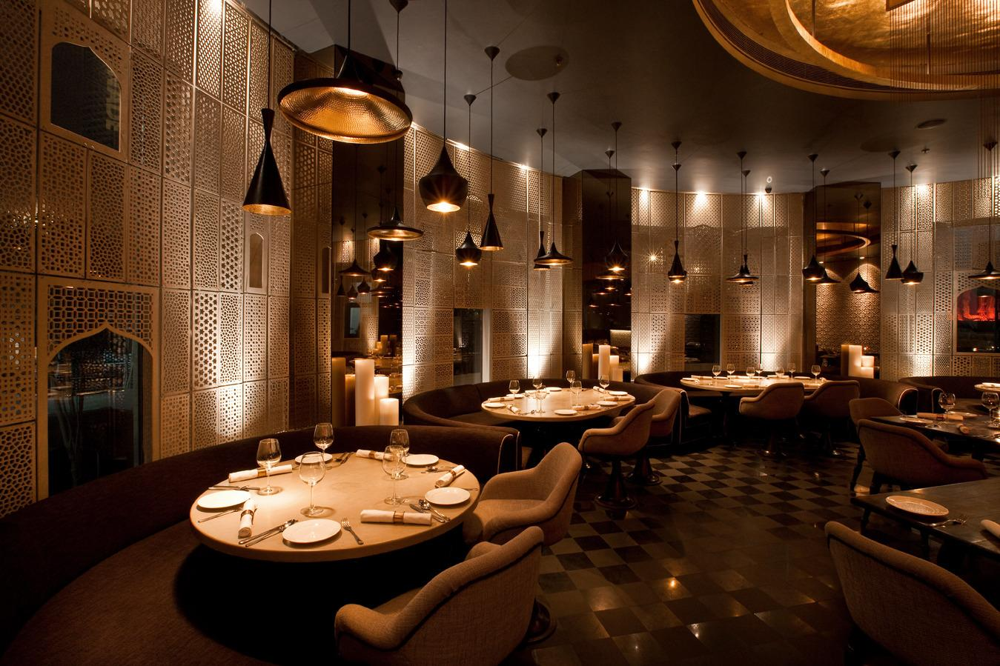

<a id="business-question"></a>
### 3.1 Business Question

**If an investor wants to open a new restaurant, what strategies will help it stand out against existing competition and attract customers?**

📍 BANGALORE, INDIA

Bangalore's restaurant market offers a wide variety of cuisines, price points, and dining experiences.   
But entering a crowded market without understanding its competitive landscape can be a costly mistake.

**OUR APPROACH**

>> 01 — MAP THE MARKET   

Understand where restaurants are concentrated and how competition varies by location.


>> 02 — DECODE THE COMPETITION   

Explore ratings, customer votes, and price positioning to understand the existing landscape.

>> 03 — FIND THE GAPS   

Investigate cuisines and restaurant formats that may be underrepresented in selected areas.


>> 04 — BUILD THE STRATEGY   

Translate the findings into evidence-based location shortlists and potential restaurant concepts.

In [410]:
COLORS = {
    "background": "#F5F1E8",
    "primary": "#25272B",
    "accent": "#B96846",
    "gold": "#C9A45C",
    "secondary": "#858585",
    "light": "#FFFFFF"
}

sns.set_theme(
    style="whitegrid",
    context="notebook",
    font_scale=1.05,
    rc={
        "figure.facecolor": COLORS["background"],
        "axes.facecolor": COLORS["background"],
        "axes.edgecolor": "#D9D2C7",
        "grid.color": "#DDD7CD",
        "grid.alpha": 0.55,
        "axes.titleweight": "bold",
        "axes.labelcolor": COLORS["primary"],
        "text.color": COLORS["primary"],
        "xtick.color": COLORS["primary"],
        "ytick.color": COLORS["primary"],
        "font.family": "DejaVu Sans"
    }
)

def style_chart(ax, title, subtitle=None):
    ax.set_title(
        title,
        loc="left",
        fontsize=17,
        fontweight="bold",
        color=COLORS["primary"],
        pad=24
    )

    if subtitle:
        ax.text(
            0, 1.02, subtitle,
            transform=ax.transAxes,
            fontsize=10,
            color=COLORS["secondary"],
            va="bottom"
        )

    ax.grid(axis="x", alpha=0.45)
    ax.grid(axis="y", visible=False)
    sns.despine(ax=ax, left=True, bottom=True)

In [411]:
eda=df.copy()

In [412]:
eda.info()

<class 'pandas.DataFrame'>
RangeIndex: 41665 entries, 0 to 41664
Data columns (total 22 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   url                          41665 non-null  str    
 1   address                      41665 non-null  str    
 2   name                         41665 non-null  str    
 3   online_order                 41665 non-null  int64  
 4   book_table                   41665 non-null  int64  
 5   rate                         41665 non-null  float64
 6   votes                        41665 non-null  int64  
 7   phone                        40851 non-null  str    
 8   location                     41665 non-null  str    
 9   rest_type                    41516 non-null  str    
 10  dish_liked                   41665 non-null  str    
 11  cuisines                     41665 non-null  str    
 12  approx_cost(for two people)  41665 non-null  float64
 13  reviews_list               

<a id="types-dishes"></a>
### 3.2 Restaurant Types and Dishes

The most common restaurant formats and the dishes associated with each.

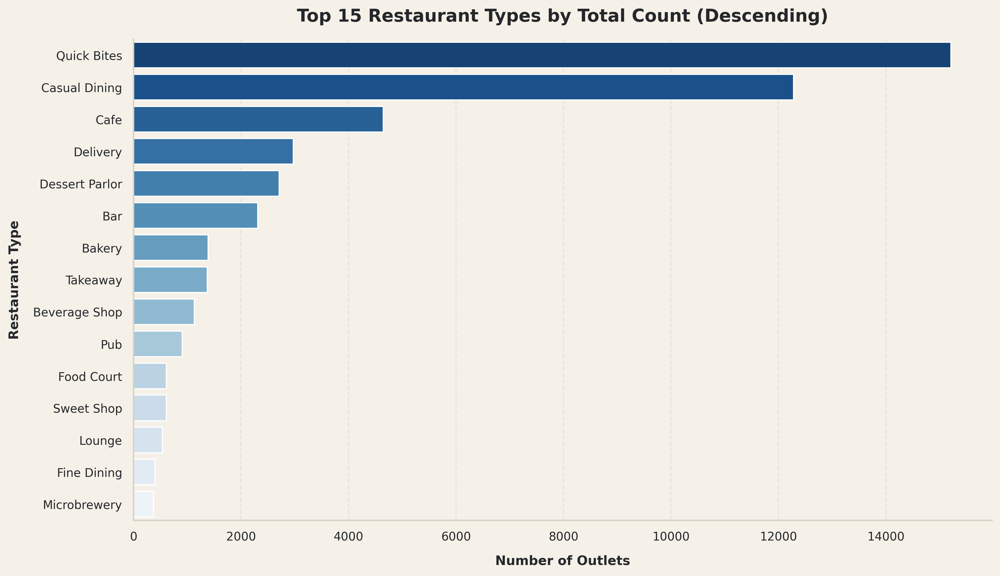

In [413]:
# --- 1. Explode and clean rest_type to count individual formats accurately ---
df_types = eda.copy()

# Split comma-separated rest_types if present
if df_types['rest_type'].dtype == 'O' or isinstance(
    df_types['rest_type'].iloc[0], str
):
  df_types['rest_type'] = df_types['rest_type'].astype(str).str.split(',')

# Explode and clean whitespace
df_types = df_types.explode('rest_type')
df_types['rest_type'] = df_types['rest_type'].astype(str).str.strip()

# Exclude non-valid / empty strings
df_types = df_types[~df_types['rest_type'].isin(['nan', 'None', '', 'NaN'])]

# --- 2. Calculate Value Counts in Descending Order ---
rest_counts = (
    df_types['rest_type'].value_counts().reset_index(name='count').head(15)
)
rest_counts.columns = ['rest_type', 'count']

# --- 3. Plot Descending Horizontal Bar Chart (Warning-Free & Clean) ---
plt.figure(figsize=(12, 7), dpi=300)

ax = sns.barplot(
    data=rest_counts,
    x='count',
    y='rest_type',
    hue='rest_type',  # Prevents Seaborn v0.14+ deprecation warning
    palette='Blues_r',
    legend=False,
    edgecolor='white',
)

plt.title(
    'Top 15 Restaurant Types by Total Count (Descending)',
    fontsize=15,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Number of Outlets', fontsize=11, fontweight='bold', labelpad=10)
plt.ylabel('Restaurant Type', fontsize=11, fontweight='bold', labelpad=10)

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

# Clean up layout
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.grid(axis='y', visible=False)
sns.despine(top=True, right=True)

plt.tight_layout()
plt.show()

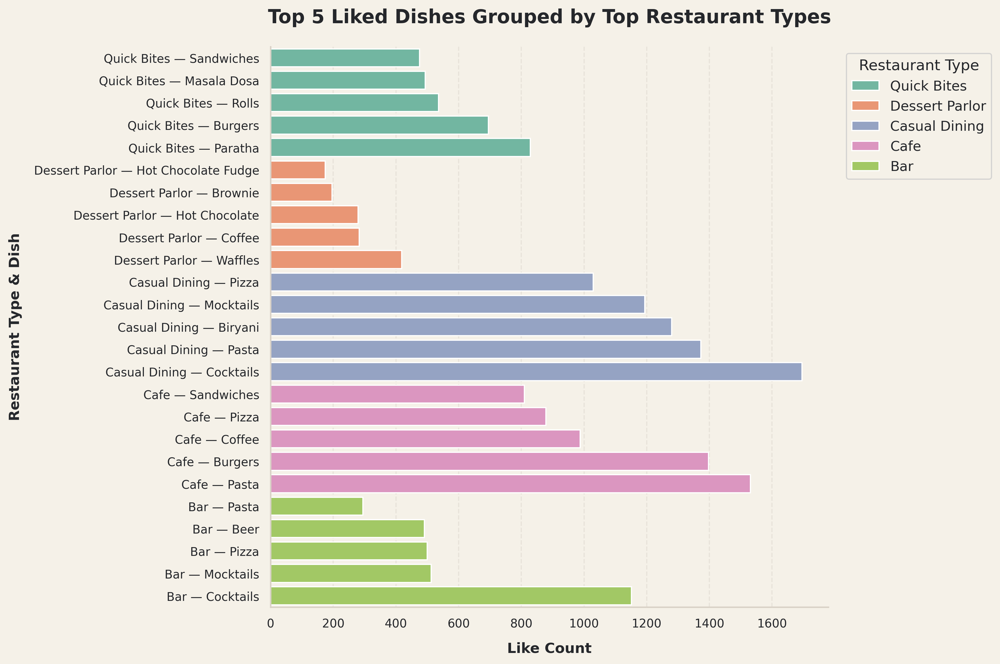

In [414]:
# --- 1. Prepare and explode data safely using 'eda' ---
df_dishes = eda.copy()

# Ensure both columns are lists before exploding
if isinstance(df_dishes['rest_type'].iloc[0], str):
  df_dishes['rest_type'] = df_dishes['rest_type'].str.split(',')
if isinstance(df_dishes['dish_liked'].iloc[0], str):
  df_dishes['dish_liked'] = df_dishes['dish_liked'].str.split(',')

df_dishes = df_dishes.explode('rest_type').reset_index(drop=True)
df_dishes = df_dishes.explode('dish_liked').reset_index(drop=True)

# --- 2. Clean text data ---
df_dishes['rest_type'] = df_dishes['rest_type'].str.strip()
df_dishes['dish_liked'] = df_dishes['dish_liked'].str.strip().str.title()

invalid_values = ['', 'Nan', 'None', 'NaN', 'Na', 'nan']
df_dishes = df_dishes[~df_dishes['dish_liked'].isin(invalid_values)]

# --- 3. Calculate Top 5 Dishes per Restaurant Type ---
dish_counts = (
    df_dishes.groupby(['rest_type', 'dish_liked'])
    .size()
    .reset_index(name='count')
)

top_5_dishes = (
    dish_counts.sort_values(['rest_type', 'count'], ascending=[True, False])
    .groupby('rest_type')
    .head(5)
    .reset_index(drop=True)
)

# --- 4. Select Top Restaurant Types to Keep It Readable ---
TOP_REST_TYPES_COUNT = 5  # Keep to top 5 types so the single plot isn't overcrowded
top_types = (
    df_dishes['rest_type'].value_counts().nlargest(TOP_REST_TYPES_COUNT).index
)
plot_data = top_5_dishes[top_5_dishes['rest_type'].isin(top_types)].copy()

# Create a combined label for the Y-axis so each dish is grouped under its restaurant type
plot_data['rest_dish'] = (
    plot_data['rest_type'] + ' — ' + plot_data['dish_liked']
)

# Sort values so they group nicely in the single plot
plot_data = plot_data.sort_values(
    by=['rest_type', 'count'], ascending=[False, True]
)

# --- 5. Generate Single Unified Plot ---
plt.figure(figsize=(12, 8), dpi=300)

ax = sns.barplot(
    data=plot_data,
    x='count',
    y='rest_dish',
    hue='rest_type',
    palette='Set2',
    dodge=False,
    edgecolor='white',
)

plt.title(
    'Top 5 Liked Dishes Grouped by Top Restaurant Types',
    fontsize=16,
    fontweight='bold',
    pad=20,
)
plt.xlabel('Like Count', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('Restaurant Type & Dish', fontsize=12, fontweight='bold', labelpad=10)

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

# Clean up legend and grid
plt.legend(
    title='Restaurant Type',
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    frameon=True,
)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.grid(axis='y', visible=False)

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

Casual Dining & Bars Drive Volume: Premium and social formats (Casual Dining and Bars) generate the highest engagement, led by high-margin items like Cocktails, Pasta, and Biryani.

Quick Bites Focus on Convenience: Fast-service outlets thrive on high-demand, portable staples like Parathas, Burgers, and Rolls.

Cafes Blend Comfort & Beverages: Cafes perform best when pairing fast food favorites (Pasta, Burgers) with staple drinks (Coffee).

<a id="performance"></a>
### 3.3 Restaurant Performance

In [415]:
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
df['name'] = df['name'].str.encode('latin1').str.decode('utf-8', errors='ignore')

**Which restaurants have the lowest ratings?**

name
Meghana Biryani                     2.300000
Biryani Junction                    2.300000
Vande Matharam                      2.300000
Bhagini                             2.283333
Taste Of Kerala                     2.240000
Mamma Mexicana                      2.200000
Bageecha                            2.150000
Decker's Lane                       2.100000
Fusion Lounge                       2.000000
Alibi - Maya International Hotel    1.800000
Name: rate, dtype: float64


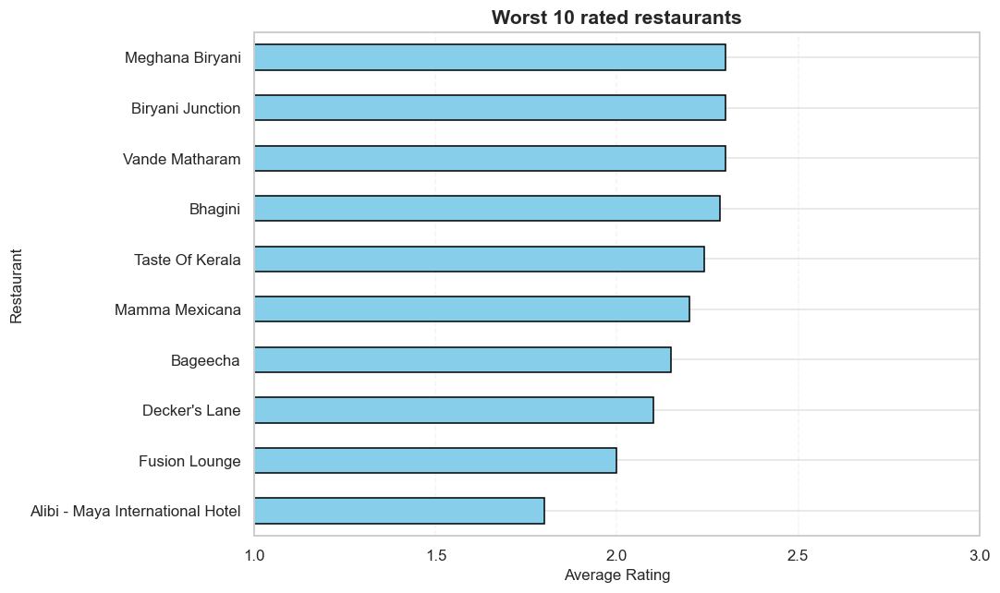

In [416]:
# average rating for each restaurant
top_rest = df.groupby("name")["rate"].mean()

# sort and get the top 10
top_rest = top_rest.sort_values(ascending=False).tail(10)

print(top_rest)

# plot
plt.figure(figsize=(10, 6))

top_rest.plot(kind="barh", color="skyblue", edgecolor="black")

plt.title("Worst 10 rated restaurants", fontsize=14)
plt.xlabel("Average Rating", fontsize=11)
plt.ylabel("Restaurant", fontsize=11)

plt.xlim(1,3)
plt.xticks([1, 1.5, 2, 2.5, 3])

plt.grid(axis="x", linestyle="--", alpha=0.2)
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

The review text of these restaurants can be examined to find the most frequent complaints.

**How does approximate cost relate to rating?**

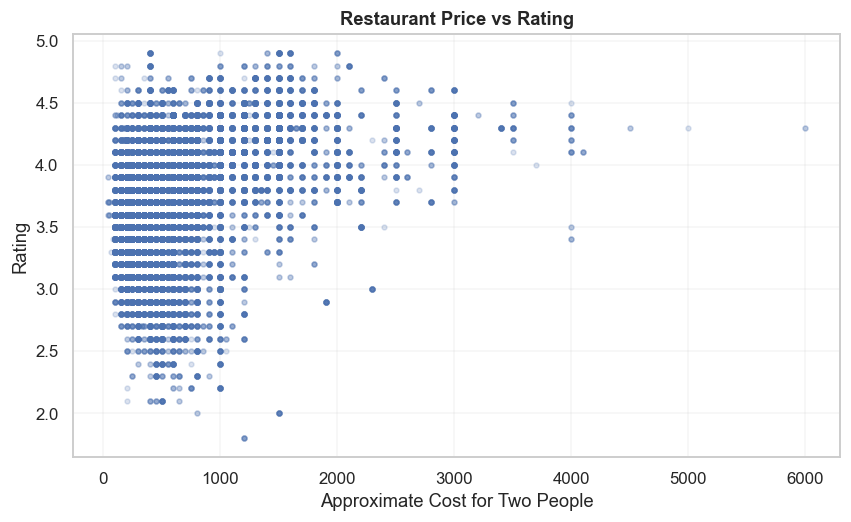

In [417]:
plt.figure(figsize=(9, 5))

plt.scatter(df['approx_cost(for two people)'], df['rate'], alpha=0.2, s=10)

plt.title('Restaurant Price vs Rating')
plt.xlabel('Approximate Cost for Two People')
plt.ylabel('Rating')
plt.grid(alpha=0.2)
plt.show()

Most restaurants are in the lower price range (under 1,000 for two), where competition is high. Very high prices do not guarantee a top score, so cheaper restaurants must compete on quality and expensive ones on service.

<a id="location-analysis"></a>
### 3.4 Location Analysis

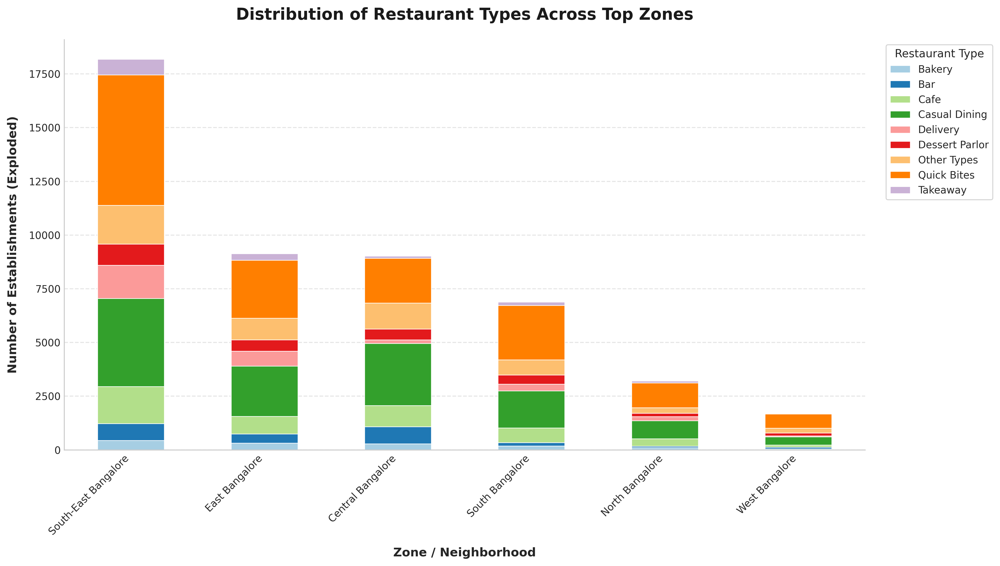

In [418]:
# --- 1. Style & Configuration ---
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']

# --- 2. Prepare and explode data safely using 'eda' ---
df_zones = eda.copy()

# Ensure rest_type is a list before exploding (checks if it's currently a string)
if isinstance(df_zones['rest_type'].iloc[0], str):
  df_zones['rest_type'] = df_zones['rest_type'].str.split(',')

# Explode rest_type and reset index to prevent duplicate label errors
df_zones = df_zones.explode('rest_type').reset_index(drop=True)
df_zones['rest_type'] = df_zones['rest_type'].str.strip()

# --- 3. Data Preparation & Long-Tail Handling ---
TOP_ZONES_COUNT = 10
TOP_TYPES_COUNT = 8

# Keep top N zones and restaurant types, group the rest as 'Other'
top_zones = df_zones['zones'].value_counts().nlargest(TOP_ZONES_COUNT).index
top_types = df_zones['rest_type'].value_counts().nlargest(TOP_TYPES_COUNT).index

df_viz = df_zones.copy()
df_viz['zone_grouped'] = df_viz['zones'].apply(
    lambda x: x if x in top_zones else 'Other Zones'
)
df_viz['rest_type_grouped'] = df_viz['rest_type'].apply(
    lambda x: x if x in top_types else 'Other Types'
)

# Create contingency table sorted by total volume
ct = pd.crosstab(df_viz['zone_grouped'], df_viz['rest_type_grouped'])
ct = ct.loc[ct.sum(axis=1).sort_values(ascending=False).index]


# --- 4. Plot: Professional Stacked Bar Chart ---
fig, ax = plt.subplots(figsize=(14, 8), dpi=300)

# Use a professional qualitative palette
colors = sns.color_palette('Paired', n_colors=len(ct.columns))
ct.plot(
    kind='bar',
    stacked=True,
    ax=ax,
    color=colors,
    edgecolor='white',
    linewidth=0.6,
)

# Typography & Formatting
ax.set_title(
    'Distribution of Restaurant Types Across Top Zones',
    fontsize=16,
    fontweight='bold',
    pad=20,
    color='#1a1a1a',
)
ax.set_xlabel(
    'Zone / Neighborhood', fontsize=12, fontweight='bold', labelpad=10
)
ax.set_ylabel(
    'Number of Establishments (Exploded)',
    fontsize=12,
    fontweight='bold',
    labelpad=10,
)

plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)

# Clean legend formatting
ax.legend(
    title='Restaurant Type',
    title_fontsize='11',
    fontsize='10',
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    frameon=True,
    facecolor='white',
    edgecolor='#cccccc',
)

ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.grid(axis='x', visible=False)

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

Busiest Hub: South-East Bangalore has the highest restaurant concentration, significantly outpacing all other zones.

Leading Formats: Casual Dining (pink) and Quick Bites (purple) dominate the market across every zone.

Consistent Distribution: While volume decreases sharply from South-East to West Bangalore, the proportional mix of restaurant types remains relatively uniform.

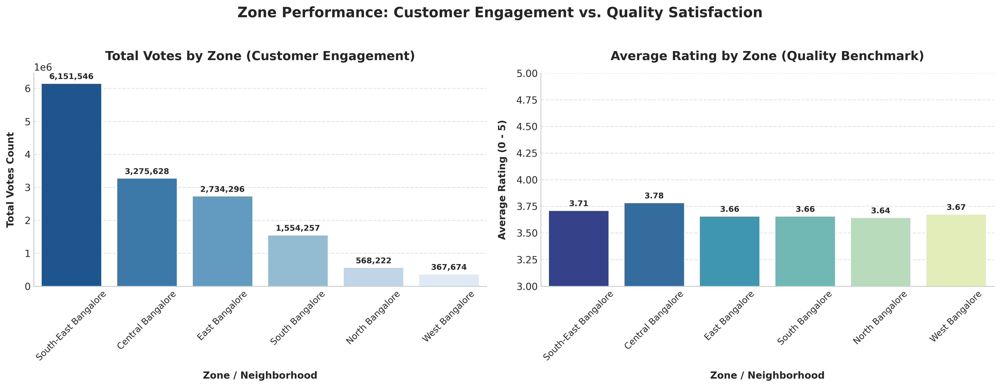

In [419]:
# --- 1. Aggregation: Calculate Average Rating and Total Votes by Zone ---
zone_summary = (
    eda.groupby('zones')
    .agg(
        avg_rating=('rate', 'mean'),
        total_votes=('votes', 'sum'),
        num_restaurants=('rate', 'count'),
    )
    .reset_index()
)

# Filter major zones (at least 50 restaurants) and select top 10 by total votes
TOP_ZONES_COUNT = 10
top_zones = (
    zone_summary[zone_summary['num_restaurants'] >= 50]
    .sort_values(by='total_votes', ascending=False)
    .head(TOP_ZONES_COUNT)
)

# --- 2. Side-by-Side Subplots ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), dpi=300)

# --- Subplot 1: Total Votes (Volume / Engagement) ---
sns.barplot(
    data=top_zones,
    x='zones',
    y='total_votes',
    hue='zones',
    palette='Blues_r',
    legend=False,
    ax=ax1,
    edgecolor='white',
)

ax1.set_title(
    'Total Votes by Zone (Customer Engagement)',
    fontsize=14,
    fontweight='bold',
    pad=15,
)
ax1.set_xlabel('Zone / Neighborhood', fontsize=11, fontweight='bold', labelpad=10)
ax1.set_ylabel('Total Votes Count', fontsize=11, fontweight='bold', labelpad=10)
ax1.tick_params(axis='x', rotation=45, labelsize=10)
ax1.grid(axis='y', linestyle='--', alpha=0.5)

# Annotate vote numbers on top of bars
for p in ax1.patches:
  height = p.get_height()
  if height > 0:
    ax1.annotate(
        f'{int(height):,}',
        (p.get_x() + p.get_width() / 2.0, height),
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold',
        xytext=(0, 3),
        textcoords='offset points',
    )

# --- Subplot 2: Average Rating (Quality / Satisfaction) ---
sns.barplot(
    data=top_zones,
    x='zones',
    y='avg_rating',
    hue='zones',
    palette='YlGnBu_r',
    legend=False,
    ax=ax2,
    edgecolor='white',
)

ax2.set_title(
    'Average Rating by Zone (Quality Benchmark)',
    fontsize=14,
    fontweight='bold',
    pad=15,
)
ax2.set_xlabel('Zone / Neighborhood', fontsize=11, fontweight='bold', labelpad=10)
ax2.set_ylabel(
    'Average Rating (0 - 5)', fontsize=11, fontweight='bold', labelpad=10
)
ax2.set_ylim(3.0, 5.0)  # Zoomed in for clearer comparison
ax2.tick_params(axis='x', rotation=45, labelsize=10)
ax2.grid(axis='y', linestyle='--', alpha=0.5)

# Annotate rating scores on top of bars
for p in ax2.patches:
  height = p.get_height()
  if height > 0:
    ax2.annotate(
        f'{height:.2f}',
        (p.get_x() + p.get_width() / 2.0, height),
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold',
        xytext=(0, 3),
        textcoords='offset points',
    )

# Clean borders
sns.despine(top=True, right=True)
plt.suptitle(
    'Zone Performance: Customer Engagement vs. Quality Satisfaction',
    fontsize=16,
    fontweight='bold',
    y=1.02,
)

plt.tight_layout()
plt.show()

Where Most People Eat: South-East Bangalore is by far the most popular area with the most customer activity, with Central and East Bangalore following behind. 

Food Quality is Good Everywhere: People like the food about the same amount no matter which part of the city they are in.   

The Best Place for New Restaurants: Central Bangalore has the happiest customers and plenty of people visiting, making it the best spot to open a cool new restaurant.   

Quieter Spots: North and West Bangalore have fewer people leaving reviews, so there is room for new places to grow there.   

**Which locations have the most restaurants?**

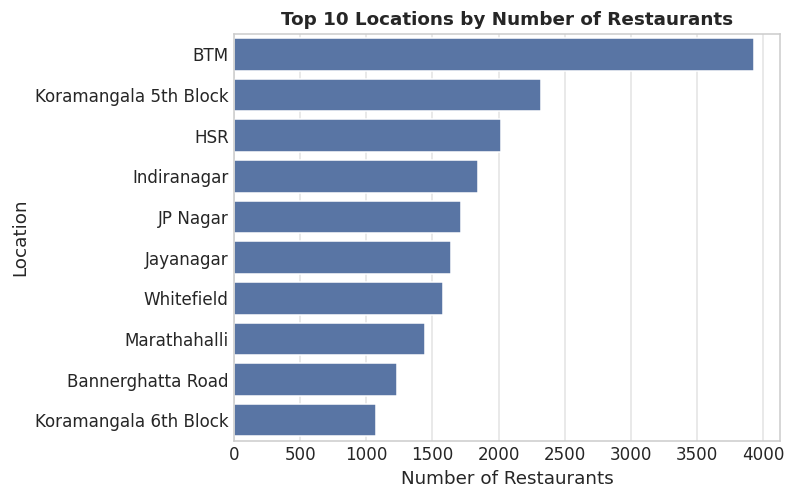

In [420]:
location_counts = df['location'].value_counts().head(10)

sns.barplot(x=location_counts.values, y=location_counts.index)

plt.title('Top 10 Locations by Number of Restaurants')
plt.xlabel('Number of Restaurants')
plt.ylabel('Location')
plt.show()

These areas may have stronger restaurant competition and a larger concentration of dining options "Ex.Food Court".

Businesses can use this information to study market demand and competition before choosing a location.

**Which locations have the most expensive restaurants?**

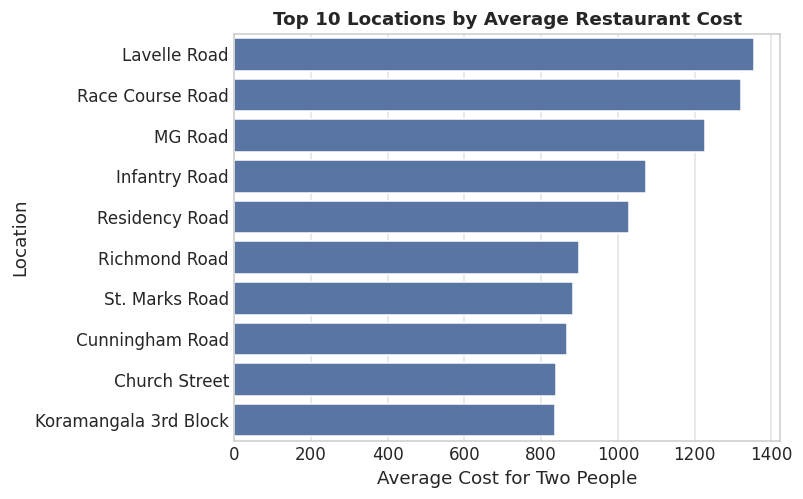

In [421]:
location_cost = df.groupby('location')['approx_cost(for two people)'].agg(['mean', 'count'])

location_cost = location_cost[location_cost['count'] >= 100]

location_cost = location_cost.sort_values('mean', ascending=False).head(10)

sns.barplot(data=location_cost.reset_index(),
            x='mean', y='location')

plt.title('Top 10 Locations by Average Restaurant Cost')
plt.xlabel('Average Cost for Two People')
plt.ylabel('Location')
plt.show()

It highlights locations with the highest average restaurant costs. These areas may be suitable for businesses targeting customers who are willing to spend more on dining.

**Which Areas Have the Greatest Variety of Cuisines?**

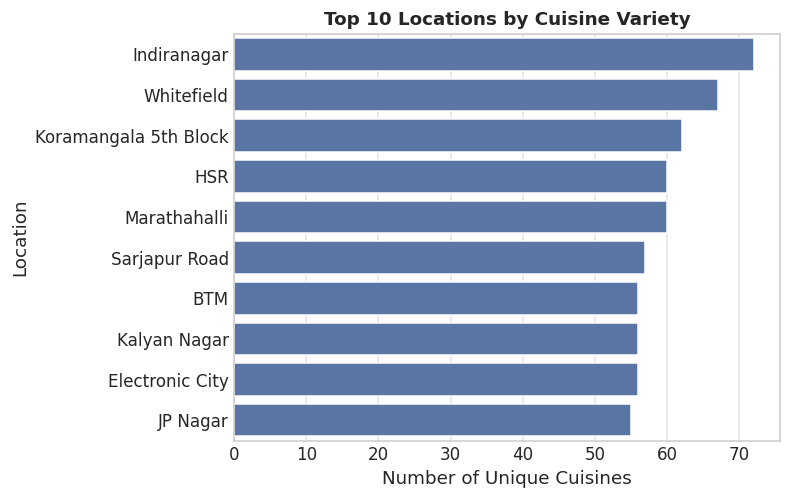

In [422]:
cuisines = df[['location', 'cuisines']].copy()

cuisines['cuisines'] = cuisines['cuisines'].str.split(',')

cuisines = cuisines.explode('cuisines')

cuisines['cuisines'] = cuisines['cuisines'].str.strip()

cuisine_variety = cuisines.groupby('location')['cuisines'].nunique()

cuisine_variety = cuisine_variety.sort_values(ascending=False).head(10)

sns.barplot(x=cuisine_variety.values, y=cuisine_variety.index)

plt.title('Top 10 Locations by Cuisine Variety')
plt.xlabel('Number of Unique Cuisines')
plt.ylabel('Location')
plt.show()

Businesses can use these findings to explore underserved cuisine categories and identify potential market opportunities. However, further analysis is needed to determine actual customer demand and competition for each cuisine.

<a id="cuisine-analysis"></a>
### 3.5 Cuisine Analysis

**What Are the Most Common Cuisines?**

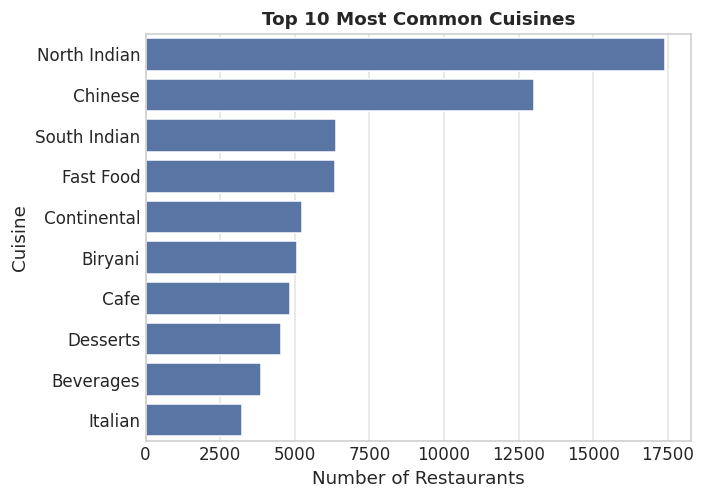

In [423]:
cuisines = df['cuisines'].str.split(',').explode().str.strip()

cuisine_counts = cuisines.value_counts().head(10)

sns.barplot(x=cuisine_counts.values, y=cuisine_counts.index)

plt.title('Top 10 Most Common Cuisines')
plt.xlabel('Number of Restaurants')
plt.ylabel('Cuisine')
plt.show()

Businesses can use these results to understand the existing market and identify cuisines with high competition.

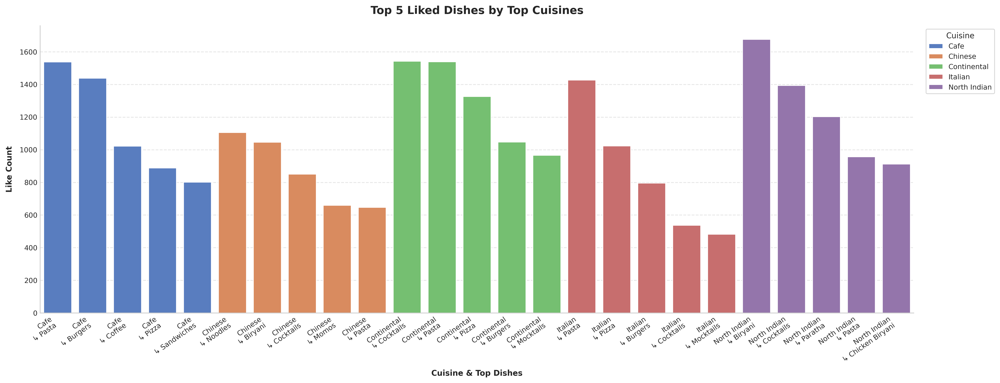

In [424]:
# --- 1. Prepare and explode data safely using 'eda' ---
df_cuisine_dishes = eda.copy()

# Ensure both columns are lists before exploding
if isinstance(df_cuisine_dishes['cuisines'].iloc[0], str):
  df_cuisine_dishes['cuisines'] = df_cuisine_dishes['cuisines'].str.split(',')
if isinstance(df_cuisine_dishes['dish_liked'].iloc[0], str):
  df_cuisine_dishes['dish_liked'] = df_cuisine_dishes['dish_liked'].str.split(',')

# Explode cuisines first, reset index, then explode dish_liked
df_cuisine_dishes = df_cuisine_dishes.explode('cuisines').reset_index(
    drop=True
)
df_cuisine_dishes = df_cuisine_dishes.explode('dish_liked').reset_index(
    drop=True
)

# --- 2. Clean text data ---
df_cuisine_dishes['cuisines'] = df_cuisine_dishes['cuisines'].str.strip()
df_cuisine_dishes['dish_liked'] = (
    df_cuisine_dishes['dish_liked'].str.strip().str.title()
)

# Filter out empty, NaN, or None values
invalid_values = ['', 'Nan', 'None', 'NaN', 'Na', 'nan']
df_cuisine_dishes = df_cuisine_dishes[
    ~df_cuisine_dishes['dish_liked'].isin(invalid_values)
]
df_cuisine_dishes = df_cuisine_dishes[
    ~df_cuisine_dishes['cuisines'].isin(invalid_values)
]

# --- 3. Calculate Top 5 Dishes per Cuisine ---
dish_counts = (
    df_cuisine_dishes.groupby(['cuisines', 'dish_liked'])
    .size()
    .reset_index(name='count')
)

top_5_dishes = (
    dish_counts.sort_values(['cuisines', 'count'], ascending=[True, False])
    .groupby('cuisines')
    .head(5)
    .reset_index(drop=True)
)

# --- 4. Select Top Cuisines ---
TOP_CUISINES_COUNT = 5
top_cuisines = (
    df_cuisine_dishes['cuisines'].value_counts().nlargest(TOP_CUISINES_COUNT).index
)
plot_data = top_5_dishes[top_5_dishes['cuisines'].isin(top_cuisines)].copy()

# Create combined labels
plot_data['cuisine_dish'] = (
    plot_data['cuisines'] + '\n↳ ' + plot_data['dish_liked']
)

# --- 5. Generate Wide Plot with Compact Elements ---
plt.figure(figsize=(18, 7), dpi=300)

ax = sns.barplot(
    data=plot_data,
    x='cuisine_dish',
    y='count',
    hue='cuisines',
    palette='muted',
    dodge=False,
    edgecolor='white',
)

# Scaled-down typography for better readability
plt.title(
    'Top 5 Liked Dishes by Top Cuisines',
    fontsize=14,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Cuisine & Top Dishes', fontsize=10, fontweight='bold', labelpad=8)
plt.ylabel('Like Count', fontsize=10, fontweight='bold', labelpad=8)

plt.xticks(rotation=35, ha='right', fontsize=9)
plt.yticks(fontsize=9)

# Compact legend formatting
plt.legend(
    title='Cuisine',
    title_fontsize='10',
    fontsize='9',
    bbox_to_anchor=(1.01, 1),
    loc='upper left',
    frameon=True,
)

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.grid(axis='x', visible=False)

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

Optimize Menus: Focus inventory and kitchen prep on proven crowd-pleasers like Pasta, Biryani, or Cocktails that naturally drive high customer engagement.   Tailor Offerings by Cuisine: Align menu additions with proven category trends—such as featuring Noodles and Momos for Chinese concepts, or various styles of Pasta and Pizza for Italian and Continental venues.   Target Marketing: Promote top-performing signature dishes to attract new foot traffic and match what diners are actively seeking out in specific neighborhoods.

**Which Cuisines Are the Most Expensive?**

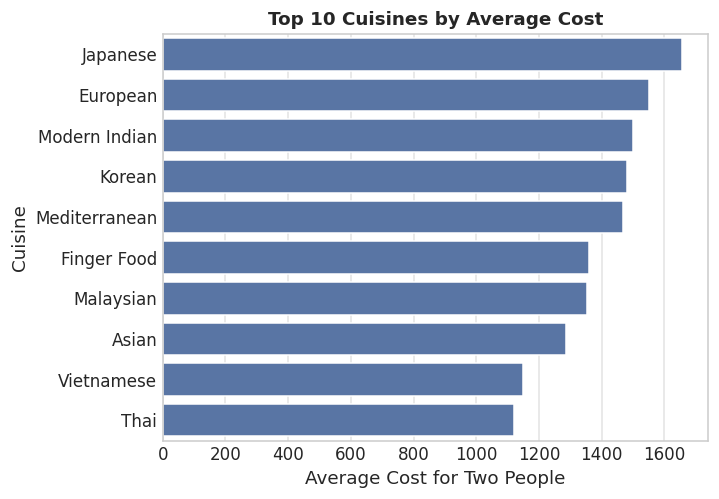

In [425]:
price_col = 'approx_cost(for two people)'

cuisines = df[['cuisines', price_col]].copy()

cuisines['cuisines'] = cuisines['cuisines'].str.split(',')
cuisines = cuisines.explode('cuisines')
cuisines['cuisines'] = cuisines['cuisines'].str.strip()

cuisine_cost = cuisines.groupby('cuisines')[price_col].agg(['mean', 'count'])
cuisine_cost = cuisine_cost[cuisine_cost['count'] >= 100]
cuisine_cost = cuisine_cost.sort_values('mean', ascending=False).head(10)

sns.barplot(data=cuisine_cost.reset_index(), x='mean', y='cuisines')

plt.title('Top 10 Cuisines by Average Cost')
plt.xlabel('Average Cost for Two People')
plt.ylabel('Cuisine')
plt.show()

This information can help businesses understand differences in restaurant pricing and explore market segments with higher dining costs.

<a id="customer-preferences"></a>
### 3.6 Customer Preferences

**Do Restaurants That Allow Table Booking Receive More Votes?**

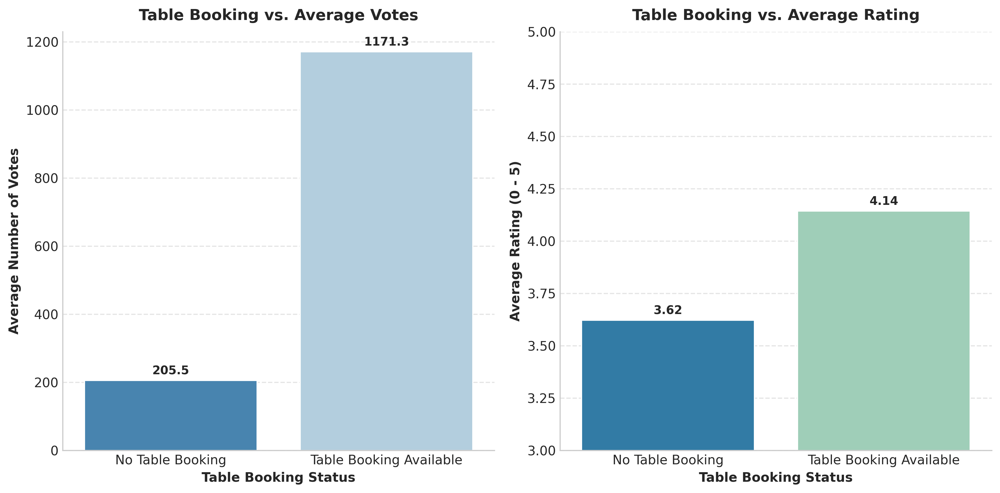

   book_table    avg_votes  avg_rating         book_table_label
0           0   205.522383    3.621470         No Table Booking
1           1  1171.342957    4.143464  Table Booking Available


In [426]:
# Group by book_table to get both mean votes and mean rate
booking_stats = (
    eda.groupby('book_table')
    .agg(avg_votes=('votes', 'mean'), avg_rating=('rate', 'mean'))
    .reset_index()
)

# Map 0/1 to readable labels
booking_stats['book_table_label'] = booking_stats['book_table'].map(
    {0: 'No Table Booking', 1: 'Table Booking Available'}
)

# Create 1x2 subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6), dpi=300)

# --- Subplot 1: Average Votes ---
sns.barplot(
    data=booking_stats,
    x='book_table_label',
    y='avg_votes',
    hue='book_table_label',
    palette='Blues_r',
    legend=False,
    ax=ax1,
    edgecolor='white',
)
ax1.set_title(
    'Table Booking vs. Average Votes', fontsize=13, fontweight='bold', pad=10
)
ax1.set_xlabel('Table Booking Status', fontsize=11, fontweight='bold')
ax1.set_ylabel('Average Number of Votes', fontsize=11, fontweight='bold')
ax1.grid(axis='y', linestyle='--', alpha=0.5)

for p in ax1.patches:
  height = p.get_height()
  if height > 0:
    ax1.annotate(
        f'{height:.1f}',
        (p.get_x() + p.get_width() / 2.0, height),
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold',
        xytext=(0, 3),
        textcoords='offset points',
    )

# --- Subplot 2: Average Rating ---
sns.barplot(
    data=booking_stats,
    x='book_table_label',
    y='avg_rating',
    hue='book_table_label',
    palette='YlGnBu_r',
    legend=False,
    ax=ax2,
    edgecolor='white',
)
ax2.set_title(
    'Table Booking vs. Average Rating', fontsize=13, fontweight='bold', pad=10
)
ax2.set_xlabel('Table Booking Status', fontsize=11, fontweight='bold')
ax2.set_ylabel('Average Rating (0 - 5)', fontsize=11, fontweight='bold')
ax2.set_ylim(3.0, 5.0)  # Zoomed in to highlight rating differences
ax2.grid(axis='y', linestyle='--', alpha=0.5)

for p in ax2.patches:
  height = p.get_height()
  if height > 0:
    ax2.annotate(
        f'{height:.2f}',
        (p.get_x() + p.get_width() / 2.0, height),
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold',
        xytext=(0, 3),
        textcoords='offset points',
    )

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

print(booking_stats)

Massive Engagement Difference: Restaurants that offer table bookings receive significantly more customer votes on average compared to those that do not. 
Higher Customer Satisfaction: Venues with table booking options achieve a notably higher average rating, showing that sit-down or upscale dining experiences generally drive better feedback.

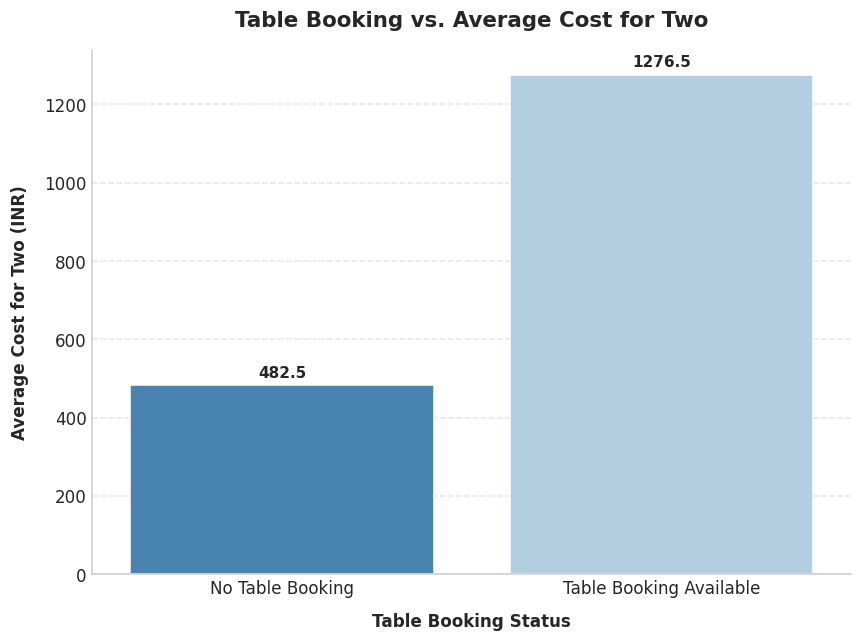

   book_table     avg_cost         book_table_label
0           0   482.527530         No Table Booking
1           1  1276.491117  Table Booking Available


In [427]:
# --- 1. Clean approx_cost if it's still a string ---
if eda['approx_cost(for two people)'].dtype == 'O':
  eda['approx_cost(for two people)'] = (
      eda['approx_cost(for two people)']
      .astype(str)
      .str.replace(',', '', regex=True)
  )
eda['approx_cost(for two people)'] = pd.to_numeric(
    eda['approx_cost(for two people)'], errors='coerce'
)

# --- 2. Group by book_table to calculate average cost ---
cost_stats = (
    eda.groupby('book_table')
    .agg(avg_cost=('approx_cost(for two people)', 'mean'))
    .reset_index()
)

# Map 0/1 to readable labels (adjust if your column uses 'Yes'/'No' strings)
cost_stats['book_table_label'] = cost_stats['book_table'].map(
    {0: 'No Table Booking', 1: 'Table Booking Available'}
)

# --- 3. Plot: Table Booking vs Average Cost ---
plt.figure(figsize=(8, 6))

ax = sns.barplot(
    data=cost_stats,
    x='book_table_label',
    y='avg_cost',
    hue='book_table_label',
    palette='Blues_r',
    legend=False,
    edgecolor='white',
)

plt.title(
    'Table Booking vs. Average Cost for Two',
    fontsize=14,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Table Booking Status', fontsize=11, fontweight='bold', labelpad=10)
plt.ylabel('Average Cost for Two (INR)', fontsize=11, fontweight='bold', labelpad=10)

plt.grid(axis='y', linestyle='--', alpha=0.5)

# Annotate cost values on top of the bars
for p in ax.patches:
  height = p.get_height()
  if height > 0:
    ax.annotate(
        f'{height:.1f}',
        (p.get_x() + p.get_width() / 2.0, height),
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold',
        xytext=(0, 3),
        textcoords='offset points',
    )

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

print(cost_stats)

Premium Pricing for Sit-Down Dining: Restaurants that offer table bookings are significantly more expensive compared to non-booking spots, proving that table reservations strongly correlate with upscale dining and higher-tier menus.

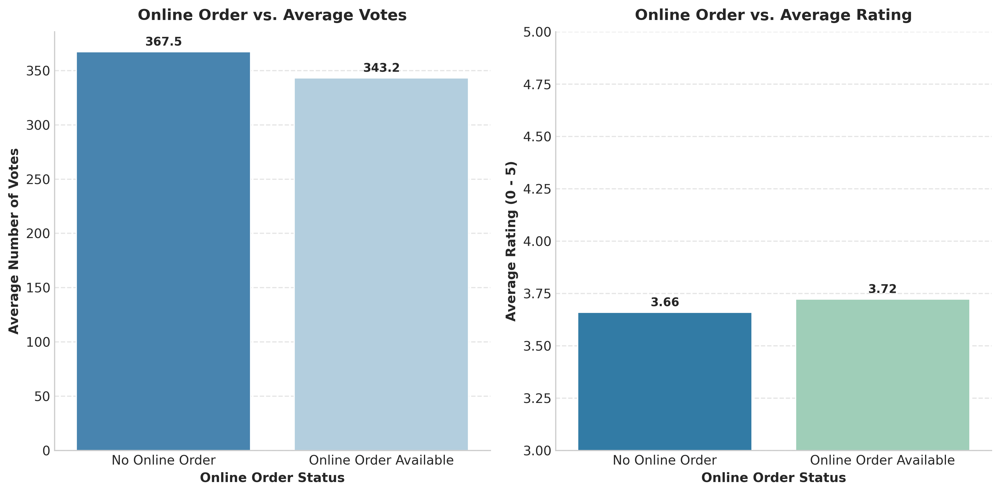

   online_order   avg_votes  avg_rating      online_order_label
0             0  367.504253     3.65907         No Online Order
1             1  343.228663     3.72244  Online Order Available


In [428]:
import matplotlib.pyplot as plt
import seaborn as sns

# Group by online_order to get both mean votes and mean rate
order_stats = (
    eda.groupby('online_order')
    .agg(avg_votes=('votes', 'mean'), avg_rating=('rate', 'mean'))
    .reset_index()
)

# Map 0/1 (or Yes/No) to readable labels
# Note: If your online_order column uses 'Yes'/'No' strings instead of 0/1,
# change the dictionary keys to {'No': 'No Online Order', 'Yes': 'Online Order Available'}
order_stats['online_order_label'] = order_stats['online_order'].map(
    {0: 'No Online Order', 1: 'Online Order Available'}
)

# Create 1x2 subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6), dpi=300)

# --- Subplot 1: Average Votes ---
sns.barplot(
    data=order_stats,
    x='online_order_label',
    y='avg_votes',
    hue='online_order_label',
    palette='Blues_r',
    legend=False,
    ax=ax1,
    edgecolor='white',
)
ax1.set_title(
    'Online Order vs. Average Votes', fontsize=13, fontweight='bold', pad=10
)
ax1.set_xlabel('Online Order Status', fontsize=11, fontweight='bold')
ax1.set_ylabel('Average Number of Votes', fontsize=11, fontweight='bold')
ax1.grid(axis='y', linestyle='--', alpha=0.5)

for p in ax1.patches:
  height = p.get_height()
  if height > 0:
    ax1.annotate(
        f'{height:.1f}',
        (p.get_x() + p.get_width() / 2.0, height),
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold',
        xytext=(0, 3),
        textcoords='offset points',
    )

# --- Subplot 2: Average Rating ---
sns.barplot(
    data=order_stats,
    x='online_order_label',
    y='avg_rating',
    hue='online_order_label',
    palette='YlGnBu_r',
    legend=False,
    ax=ax2,
    edgecolor='white',
)
ax2.set_title(
    'Online Order vs. Average Rating', fontsize=13, fontweight='bold', pad=10
)
ax2.set_xlabel('Online Order Status', fontsize=11, fontweight='bold')
ax2.set_ylabel('Average Rating (0 - 5)', fontsize=11, fontweight='bold')
ax2.set_ylim(3.0, 5.0)  # Zoomed in to highlight rating differences
ax2.grid(axis='y', linestyle='--', alpha=0.5)

for p in ax2.patches:
  height = p.get_height()
  if height > 0:
    ax2.annotate(
        f'{height:.2f}',
        (p.get_x() + p.get_width() / 2.0, height),
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold',
        xytext=(0, 3),
        textcoords='offset points',
    )

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

print(order_stats)

Table Booking is a Game Changer: Offering table bookings means much happier customers and way more reviews/votes, meaning people care more about sit-down dining experiences.   
Online Ordering is Just Normal: Having online ordering doesn't make a restaurant stand out as much—almost everyone offers it, so ratings and votes stay pretty much the same whether they have it or not. 

<a id="pricing-analysis"></a>
### 3.7 Pricing Analysis

**What Is the Average Cost for Two People?**

Average cost for two people: 602.66


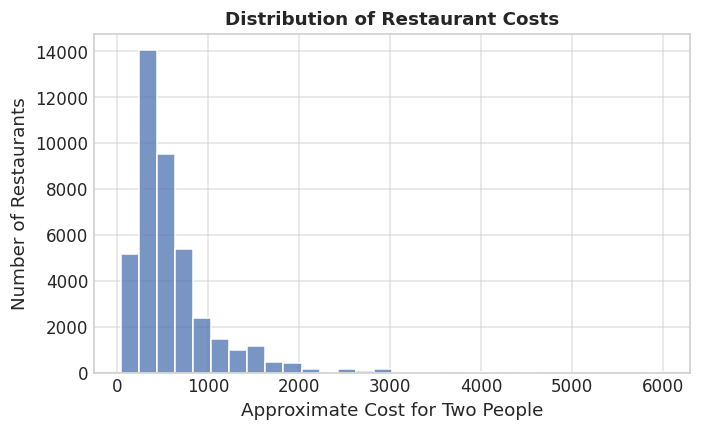

In [429]:
price_col = 'approx_cost(for two people)'

avg_cost = df[price_col].mean()

print(f"Average cost for two people: {avg_cost:.2f}")

plt.figure(figsize=(7, 4))
sns.histplot(df[price_col], bins=30)

plt.title('Distribution of Restaurant Costs')
plt.xlabel('Approximate Cost for Two People')
plt.ylabel('Number of Restaurants')
plt.show()

Businesses can use this information to understand the overall pricing landscape and compare their prices with the market.

**How Does Restaurant Type Affect Pricing?**

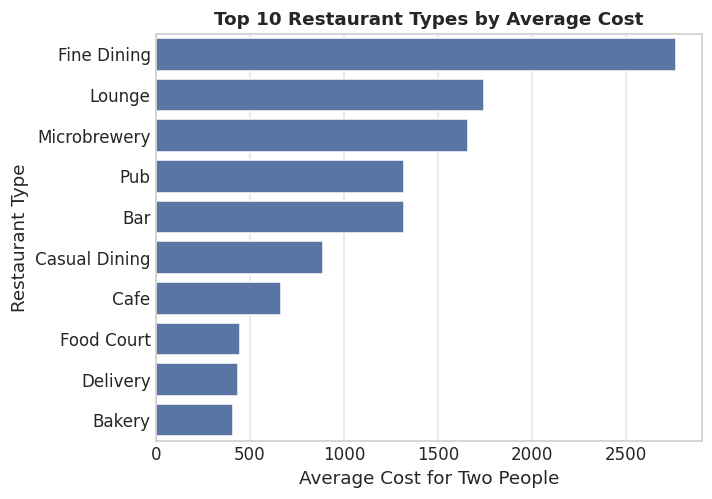

In [430]:
type_cost = df[['rest_type', price_col]].copy()

type_cost['rest_type'] = type_cost['rest_type'].str.split(',')

type_cost = type_cost.explode('rest_type')

type_cost['rest_type'] = type_cost['rest_type'].str.strip()

type_cost = type_cost.groupby('rest_type')[price_col].agg(['mean', 'count'])

type_cost = type_cost[type_cost['count'] >= 100]

type_cost = type_cost.sort_values('mean', ascending=False).head(10)

sns.barplot(data=type_cost.reset_index(), x='mean', y='rest_type')

plt.title('Top 10 Restaurant Types by Average Cost')
plt.xlabel('Average Cost for Two People')
plt.ylabel('Restaurant Type')
plt.show()

This can help businesses understand pricing differences between restaurant categories and identify market segments with different spending levels.

<a id="ratings-market"></a>
### 3.8 Ratings and Market Comparison

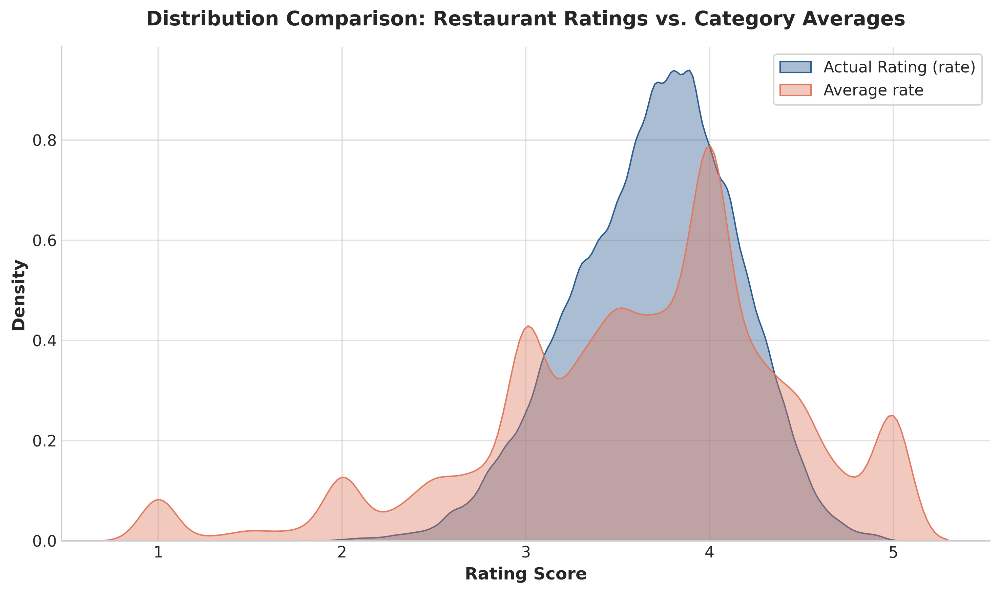

In [431]:
plt.figure(figsize=(10, 6), dpi=300)
sns.kdeplot(eda['rate'], label='Actual Rating (rate)', fill=True, color='#2b5c8f', alpha=0.4)
sns.kdeplot(eda['avg_rate'], label='Average rate', fill=True, color='#e07a5f', alpha=0.4)

plt.title('Distribution Comparison: Restaurant Ratings vs. Category Averages', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Rating Score', fontsize=12, fontweight='bold')
plt.ylabel('Density', fontsize=12, fontweight='bold')
plt.legend(frameon=True)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

Overall Positive Sentiment Skew: Both official ratings (rate) and customer text feedback benchmarks (Average rate) heavily cluster and peak between 3.5 and 4.2, showing that the vast majority of restaurants maintain a solid, favorable standard.

Sentiment Polarization: The Average rate distribution curve shows distinct secondary peaks (nodes around 2.0 and 5.0), indicating that customer reviews extracted from text tend to be more polarized—capturing stronger emotional extremes (both enthusiastic praise and harsh criticism) than official platform ratings.

Platform vs. Review Alignment: The close overlap of the curves in the 3.5–4.5 range proves that official ratings align well with general customer sentiment, validating the reliability of both metrics as trustworthy proxies for restaurant performance.

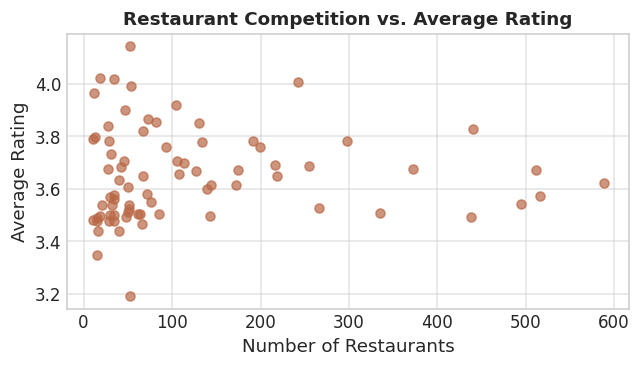

,restaurants,avg_rating
location,,
Whitefield,588,3.62
BTM,516,3.57
HSR,512,3.67
Marathahalli,495,3.54
Indiranagar,440,3.83
Electronic City,438,3.49
JP Nagar,373,3.68
Bannerghatta Road,335,3.51
Jayanagar,298,3.78


In [432]:
market = eda.groupby('location').agg(
    restaurants=('name', 'nunique'),
    avg_rating=('rate', 'mean')
).dropna()

market = market[market['restaurants'] >= 10]

plt.figure(figsize=(6, 3.5))
plt.scatter(market['restaurants'], market['avg_rating'],
            s=35, alpha=0.7, color='#B96846')
plt.title('Restaurant Competition vs. Average Rating')
plt.xlabel('Number of Restaurants')
plt.ylabel('Average Rating')
plt.tight_layout()
plt.show()

display(market.sort_values('restaurants', ascending=False).head(10).round(2))

### What Does This Tell Us?

**Key Observation:** Whitefield has the most restaurants (570), with an average rating of 3.62. Indiranagar has fewer restaurants (435) but the highest average rating (3.83). Electronic City has 417 restaurants and a lower average rating of 3.50.

**Business Interpretation:** More restaurants do not always mean higher ratings. Some locations have fewer restaurants but better customer ratings.

**Investor Implication:** Indiranagar may be worth studying because of its high average rating, while locations with lower ratings may need more research to understand customer needs.

**Business Insight:** Restaurant counts and ratings help us compare locations, but they do not tell us actual demand or profit. More research is needed before choosing a location.

**Cuisines compared by rating and cost**

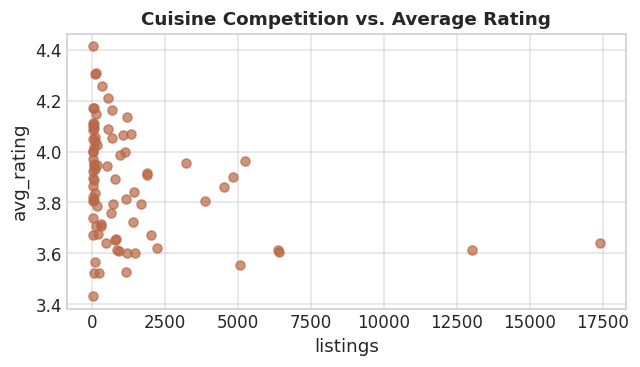

,listings,avg_rating,avg_cost
cuisine,,,
Roast Chicken,21,3.67,338.10
Kashmiri,22,3.43,759.09
Bar Food,23,3.80,1191.30
Grill,24,3.74,1808.33
Naga,25,4.11,728.00
Assamese,25,3.97,644.00
Awadhi,27,3.93,707.41
Iranian,29,3.90,944.83
Parsi,29,4.10,1031.03


In [433]:
c = eda[['cuisines', 'rate', 'approx_cost(for two people)']].dropna().copy()
c['cuisine'] = c['cuisines'].str.split(',')
c = c.explode('cuisine')
c['cuisine'] = c['cuisine'].str.strip()

summary = c.groupby('cuisine').agg(
    listings=('cuisine', 'size'),
    avg_rating=('rate', 'mean'),
    avg_cost=('approx_cost(for two people)', 'mean')
)
summary = summary[summary['listings'] >= 20]

summary.plot.scatter(x='listings', y='avg_rating',
                     s=35, alpha=0.7, color='#B96846',
                     figsize=(6, 3.5),
                     title='Cuisine Competition vs. Average Rating')

plt.tight_layout()
plt.show()

display(summary.sort_values('listings').head(10).round(2))

**Rating by price segment:** restaurants are split into four price segments. Average rating rises with price, from 3.57 (Budget) and 3.60 (Affordable) to 3.69 (Premium) and 3.99 (High-End).

,Restaurants,Avg_Rating
Price Segment,,
Budget,12587,3.57
Affordable,12235,3.60
Premium,6492,3.69
High-End,10351,3.99


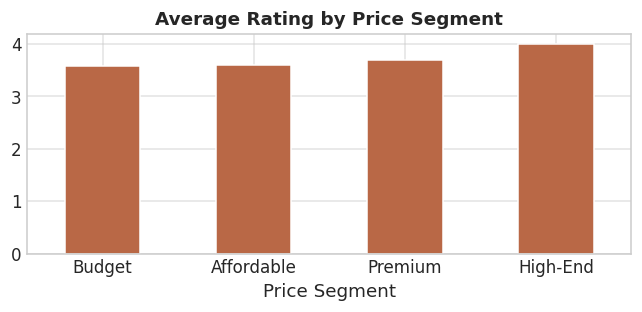

In [434]:
data = eda[['approx_cost(for two people)', 'rate']].dropna()
data['Price Segment'] = pd.qcut(data['approx_cost(for two people)'], 4,
                                labels=['Budget', 'Affordable', 'Premium', 'High-End'])

summary = data.groupby('Price Segment', observed=True).agg(
    Restaurants=('rate', 'count'),
    Avg_Rating=('rate', 'mean')
).round(2)

display(summary)

summary['Avg_Rating'].plot(kind='bar', figsize=(6, 3), color='#B96846',
                           title='Average Rating by Price Segment')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

<a id="encoding"></a>
## 4. Feature Encoding

The 20 most frequent cuisines are multi-hot encoded into binary columns so they can be used by the models. The cells below check the resulting columns (42 in total).

In [435]:
# Multi-Hot Encoding for top 20 cuisines
cuisine_lists = df['cuisines'].apply(lambda x: [c.strip().lower() for c in x.split(',') if c.strip()])
mlb_cuisines = MultiLabelBinarizer()
cuisines_encoded = pd.DataFrame(mlb_cuisines.fit_transform(cuisine_lists), columns=[f"cuisine_{c}" for c in mlb_cuisines.classes_], index=df.index)

top_cuisines = cuisines_encoded.sum().sort_values(ascending=False).head(20).index
df = pd.concat([df, cuisines_encoded[top_cuisines]], axis=1)

In [436]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41665 entries, 0 to 41664
Data columns (total 42 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   url                          41665 non-null  str    
 1   address                      41665 non-null  str    
 2   name                         41665 non-null  str    
 3   online_order                 41665 non-null  int64  
 4   book_table                   41665 non-null  int64  
 5   rate                         41665 non-null  float64
 6   votes                        41665 non-null  int64  
 7   phone                        40851 non-null  str    
 8   location                     41665 non-null  str    
 9   rest_type                    41516 non-null  str    
 10  dish_liked                   41665 non-null  str    
 11  cuisines                     41665 non-null  str    
 12  approx_cost(for two people)  41665 non-null  float64
 13  reviews_list               

In [437]:
df.head()

,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,...,cuisine_street food,cuisine_bakery,cuisine_pizza,cuisine_burger,cuisine_seafood,cuisine_andhra,cuisine_ice cream,cuisine_mughlai,cuisine_american,cuisine_asian
0,https://www.zomato.com/bangalore/jalsa-banasha...,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,1,1,4.1,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,...,0,0,0,0,0,0,0,1,0,0
1,https://www.zomato.com/bangalore/spice-elephan...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,1,0,4.1,787,080 41714161,Banashankari,Casual Dining,...,0,0,0,0,0,0,0,0,0,0
2,https://www.zomato.com/SanchurroBangalore?cont...,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,1,0,3.8,918,+91 9663487993,Banashankari,"Cafe, Casual Dining",...,0,0,0,0,0,0,0,0,0,0
3,https://www.zomato.com/bangalore/addhuri-udupi...,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,0,0,3.7,88,+91 9620009302,Banashankari,Quick Bites,...,0,0,0,0,0,0,0,0,0,0
4,https://www.zomato.com/bangalore/grand-village...,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,0,0,3.8,166,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,...,0,0,0,0,0,0,0,0,0,0


In [438]:
df.columns

Index(['url', 'address', 'name', 'online_order', 'book_table', 'rate', 'votes',
       'phone', 'location', 'rest_type', 'dish_liked', 'cuisines',
       'approx_cost(for two people)', 'reviews_list', 'menu_item',
       'listed_in(type)', 'listed_in(city)', 'zones', 'avg_rate',
       'dish_liked_count', 'dish_liked_score', 'num_cuisines',
       'cuisine_north indian', 'cuisine_chinese', 'cuisine_south indian',
       'cuisine_fast food', 'cuisine_continental', 'cuisine_biryani',
       'cuisine_cafe', 'cuisine_desserts', 'cuisine_beverages',
       'cuisine_italian', 'cuisine_street food', 'cuisine_bakery',
       'cuisine_pizza', 'cuisine_burger', 'cuisine_seafood', 'cuisine_andhra',
       'cuisine_ice cream', 'cuisine_mughlai', 'cuisine_american',
       'cuisine_asian'],
      dtype='str')

<a id="modelling"></a>
## 5. Machine Learning Modelling

The modelling follows six steps: screen single features, fit simple baselines, move to a group-aware split so no restaurant appears in both sets, improve generalization, compare regression models, and compare classification models. Regression is scored with MSE/RMSE/MAE/R²; classification with Accuracy, Precision, Recall, F1 and ROC-AUC.

<a id="approach"></a>
### 5.1 Approach

## 🧠 "Be stupid first. Let the data teach you how to be smart." 🔥

> **"Be stupid first, so you can be smart later."**

Don't try to be perfect from the beginning. Start with the simplest model, even if it performs poorly.

Learn from its mistakes, understand its limitations, and gradually make it smarter by increasing complexity when needed.

**Our philosophy:**
- Be stupid first.
- Learn from your mistakes.
- Improve step by step.
- Be smart in the end.

Because in Machine Learning, **you can't appreciate improvement without a starting point!**

In [439]:

# 1. Load data
df2 = pd.read_csv("zomato.csv")

# 2. Clean target: rate
df2["rate"] = (
    df2["rate"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s*/\s*5$", "", regex=True)
)
# 3. Select useful features
features = [
    "book_table",
    "votes",
    "location",
    "rest_type",
    "cuisines",
    "approx_cost(for two people)",
    "listed_in(type)",
    "listed_in(city)",
    "dish_liked"
]

df2["rate"] = pd.to_numeric(df2["rate"], errors="coerce")

# Remove rows with missing target
df2 = df2.dropna(subset=["rate"]).copy()

from sklearn.model_selection import train_test_split

X = df2[features].copy()
y = df2["rate"].copy()

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Keep only features that exist in the dataset
features = [f for f in features if f in df2.columns]

X = df2[features].copy()
y = df2["rate"]

# Convert numeric-looking columns to numeric
for col in ["votes", "approx_cost(for two people)"]:
    if col in X.columns:
        X[col] = pd.to_numeric(
            X[col].astype("string").str.replace(",", "", regex=False),
            errors="coerce"
        )

# 4. Split data
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# 5. Evaluate each feature individually
results = []

for feature in features:

    # Detect numerical vs categorical
    if pd.api.types.is_numeric_dtype(X_train[feature]):
        transformer = Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ])
    else:
        transformer = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ])

    preprocessor = ColumnTransformer([
        ("feature", transformer, [feature])
    ])

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ])

    # Train
    model.fit(X_train[[feature]], y_train)

    # Predict
    y_pred = model.predict(X_val[[feature]])

    # Evaluate
    mse = mean_squared_error(y_val, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_val, y_pred)

    results.append({
        "Feature": feature,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

# 6. Display results
results_df = pd.DataFrame(results).sort_values("RMSE")

print("\nFeature Evaluation Results:")
print(results_df.to_string(index=False))



Feature Evaluation Results:
                    Feature      MSE     RMSE       R2
                 dish_liked 0.048907 0.221150 0.747201
                   cuisines 0.102580 0.320280 0.469771
                      votes 0.156730 0.395891 0.189872
                  rest_type 0.159599 0.399498 0.175041
                 book_table 0.160436 0.400545 0.170713
approx_cost(for two people) 0.167401 0.409147 0.134712
                   location 0.170586 0.413020 0.118251
            listed_in(type) 0.186443 0.431791 0.036285
            listed_in(city) 0.188805 0.434518 0.024074


Before building complex models, we start by evaluating each feature individually to understand its predictive power.

#### What Did We Learn?

- **`dish_liked`** achieved the best individual performance, with an R² score of **0.7472**.
- **`cuisines`** ranked second, with an R² score of **0.4698**.
- **`listed_in(type)`** and **`listed_in(city)`** showed very limited individual predictive power, with R² scores of **0.0363** and **0.0241**, respectively.

#### Key Takeaway

Not every feature contributes equally to predicting restaurant ratings. Starting with simple experiments helps us identify promising features before moving to more complex models.

**Our approach: Start simple, learn from the results, and improve step by step.**

*Note: Individual feature performance does not necessarily reflect its contribution when combined with other features. Further evaluation is required.*

<a id="screening"></a>
### 5.2 Single-Feature Screening

Each feature is evaluated on its own to see how much it predicts the rating.

- `dish_liked` is the strongest single feature (R² = 0.7472), followed by `cuisines` (R² = 0.4698).
- `listed_in(type)` and `listed_in(city)` are weak predictors (R² = 0.0363 and 0.0241).

In [440]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


selected_features = ["cuisines"  ,"dish_liked"]

categorical_features = ["cuisines" ,"dish_liked"]
numerical_features = []


preprocessor = ColumnTransformer([
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]),
        categorical_features
    ),
    (
        "num",
        SimpleImputer(strategy="median"),
        numerical_features
    )
])


# Model pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

model.fit(X_train[selected_features], y_train)


# Predict
y_pred = model.predict(X_val[selected_features])

# Evaluate
print("MSE:", mean_squared_error(y_val, y_pred))
print("R2:", r2_score(y_val, y_pred))

MSE: 0.035340381143180596
R2: 0.8173273157642856


### 🐐 Be the GOAT, Not Just a Goat!

#### Starting Small: Two Features

We begin with a simple model using only two categorical features: `cuisines` and `dish_liked`.

The goal is to establish an initial performance baseline before experimenting with additional features and more complex configurations.

**Initial Results:**
- **MSE:** 0.0353
- **R² Score:** 0.8173

Even with only two features, the model achieves a promising R² score of approximately **81.73%** on the validation set.

This gives us a starting point to investigate whether adding more features can improve predictive performance.

**Let's start simple, learn from the results, and build our way toward a better model!**

In [441]:
selected_features = [
    "cuisines",
    "votes",
    "rest_type",
    "book_table"
    ,"dish_liked"
]

categorical_features = [
    "cuisines",
    "rest_type",
    "book_table","dish_liked"
]

numerical_features = ["votes"]

preprocessor = ColumnTransformer([
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]),
        categorical_features
    ),
    (
        "num",
        SimpleImputer(strategy="median"),
        numerical_features
    )
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

model.fit(X_train[selected_features], y_train)

y_pred = model.predict(X_val[selected_features])

print("MSE:", mean_squared_error(y_val, y_pred))
print("R2:", r2_score(y_val, y_pred))

MSE: 0.03466778167898204
R2: 0.8208039491668193


**Five features** (`cuisines`, `votes`, `rest_type`, `book_table`, `dish_liked`): the model uses a pipeline with one-hot encoding for categorical features and median imputation for numeric features. Validation MSE = 0.0347 and R² = 0.8208.

## 🎯 No False Promises: Honesty Before Accuracy

> **"We don't sell illusions. We build models that generalize."**

In Machine Learning, achieving a high validation score is not enough. A model may appear highly accurate simply because the evaluation setup allows it to learn patterns that will not be available in real-world scenarios.

Our priority is not to produce impressive numbers just to make the model look successful. **Our priority is to build a model whose predictions can be trusted.**

### Why GroupShuffleSplit?

If records belonging to the same restaurant appear in both the training and validation sets, the evaluation may overestimate how well the model performs on unseen restaurants.

To reduce this risk, we use `GroupShuffleSplit`, grouping records by restaurant name so that the same group does not appear in both sets.

This helps us evaluate whether the model can learn meaningful patterns that generalize beyond the restaurants it has already seen.

### Our Principles

- **Honesty over impressive scores:** A realistic result is more valuable than an inflated one.
- **Generalization over memorization:** The model should learn useful patterns, not simply recognize familiar restaurants.
- **Trust over false promises:** We must never claim that a model is reliable without evidence.
- **Real-world performance over notebook performance:** Validation results should reflect the conditions in which the model will actually be used.

### Our Goal

We aim to build a model that performs reliably on unseen data, communicates its limitations honestly, and provides predictions without creating unrealistic expectations.

**A trustworthy model is not the one that promises the most. It is the one that delivers what its evidence supports.**

In [442]:

from sklearn.model_selection import GroupShuffleSplit

selected_features = [
    "cuisines",
    "votes",
    "rest_type",
    "book_table","dish_liked"
]

X = df[selected_features].copy()
y = df["rate"].copy()
groups = df["name"].fillna("UNKNOWN_RESTAURANT").copy()

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(
    gss.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_val = X.iloc[val_idx]

y_train = y.iloc[train_idx]
y_val = y.iloc[val_idx]

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))

print(
    "Overlapping restaurant names:",
    len(set(groups.iloc[train_idx]) &
        set(groups.iloc[val_idx]))
)

Training rows: 33541
Validation rows: 8124
Overlapping restaurant names: 0


In [443]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

selected_features = [
    "cuisines",
    "votes",
    "rest_type",
    "book_table","dish_liked"
]

categorical_features = [
    "cuisines",
    "rest_type",
    "book_table","dish_liked"
]

numerical_features = ["votes"]

preprocessor = ColumnTransformer([
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]),
        categorical_features
    ),
    (
        "num",
        SimpleImputer(strategy="median"),
        numerical_features
    )
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

model.fit(X_train, y_train)

y_pred = model.predict(X_val)

print("MSE:", mean_squared_error(y_val, y_pred))
print("R2:", r2_score(y_val, y_pred))

MSE: 0.12388150565708832
R2: 0.36947392340246143


Re-fitting the same Linear Regression on the grouped split gives MSE = 0.1239 and R² = 0.3695, down from 0.8208. This suggests the random-split score was too optimistic, so the grouped split is used from here on.

In [444]:
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score

# Create log_votes without changing the original split
X_train_exp = X_train.copy()
X_val_exp = X_val.copy()

X_train_exp["log_votes"] = np.log1p(
    X_train_exp["votes"].clip(lower=0)
)
X_val_exp["log_votes"] = np.log1p(
    X_val_exp["votes"].clip(lower=0)
)

categorical_features = [
    "cuisines",
    "rest_type",
    "book_table",
    "dish_liked"
]

numerical_features = ["log_votes"]

preprocessor = ColumnTransformer([
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=10
            ))
        ]),
        categorical_features
    ),
    (
        "num",
        SimpleImputer(strategy="median"),
        numerical_features
    )
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Ridge(alpha=10))
])

model.fit(X_train_exp, y_train)

y_pred = model.predict(X_val_exp)

print("MSE:", mean_squared_error(y_val, y_pred))
print("R2:", r2_score(y_val, y_pred))

MSE: 0.10715946990431295
R2: 0.4545849296014559


![WhatsApp Image 2026-10-13 at 5.44.38 PM.jpeg](<attachment:WhatsApp Image 2026-10-13 at 5.44.38 PM.jpeg>)
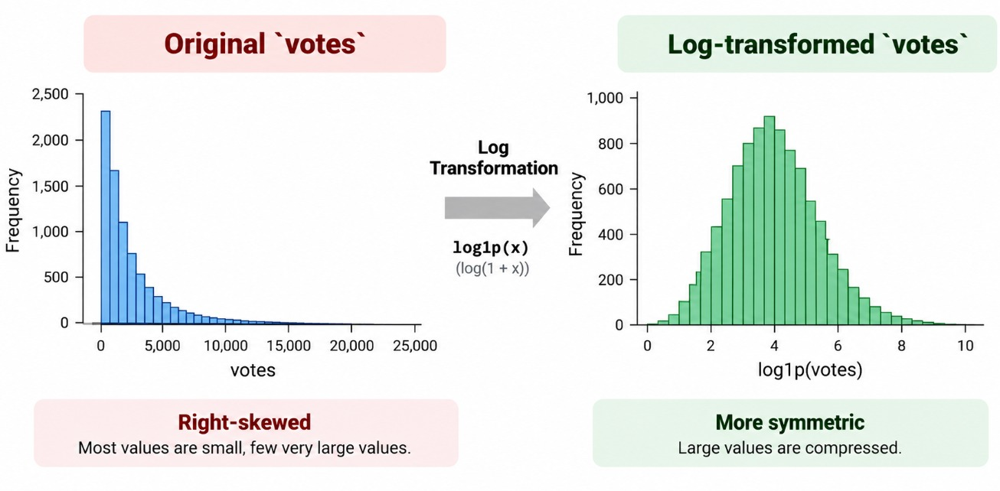

<a id="generalization"></a>
### 5.5 Improving Generalization

Changes applied: a log transform of `votes`, one-hot encoding with `min_frequency=10`, imputation of missing values, and `Ridge(alpha=10)` to limit overfitting.

**Result:** MSE = 0.1072 and R² = 0.4546 on the grouped validation set, an improvement over the grouped Linear Regression baseline (R² = 0.3695).

<a id="regression"></a>
### 5.6 Regression Model Comparison

Nine regression models are compared on the same grouped train/test split, using engineered features such as `avg_rate`, `votes` (log-transformed), cost, dish features and cuisine indicators.

In [452]:
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor


def evaluate_regression_models(X, y, groups, test_size=0.2, random_state=42):
    gss = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=random_state)
    train_idx, test_idx = next(gss.split(X, y, groups=groups))

    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    models = {
        'Linear Regression': LinearRegression(),
        'Ridge Regression (alpha=1.0)': Ridge(alpha=1.0),
        'Lasso Regression (alpha=0.01)': Lasso(alpha=0.01),
        'Polynomial Regression (Degree 2)': make_pipeline(
            PolynomialFeatures(degree=2), LinearRegression()
        ),
        'Polynomial Regression (Degree 3)': make_pipeline(
            PolynomialFeatures(degree=3), LinearRegression()
        ),
        'KNN Regressor (n_neighbors=5)': KNeighborsRegressor(n_neighbors=5),
        'Decision Tree Regressor': DecisionTreeRegressor(random_state=random_state),
        'Random Forest Regressor': RandomForestRegressor(
            n_estimators=100, random_state=random_state
        ),
        'XGBoost Regressor': XGBRegressor(
            n_estimators=100, learning_rate=0.1, max_depth=6, random_state=random_state
        )
    }

    results = []

    for name, model in models.items():
        model.fit(X_train_scaled, y_train)
        preds = model.predict(X_test_scaled)

        rmse = np.sqrt(mean_squared_error(y_test, preds))
        mae = mean_absolute_error(y_test, preds)
        r2 = r2_score(y_test, preds)

        results.append({
            'Model': name,
            'RMSE': round(rmse, 4),
            'MAE': round(mae, 4),
            'R² Score': round(r2, 4)
        })

    return pd.DataFrame(results)

In [453]:

feature_cols = [
    'online_order', 'book_table', 'votes', 'approx_cost(for two people)',
    'avg_rate', 'dish_liked_count', 'num_cuisines', 'cuisine_north indian',
    'cuisine_chinese', 'cuisine_south indian', 'cuisine_fast food',
    'cuisine_continental', 'cuisine_biryani', 'cuisine_cafe', 'cuisine_desserts',
    'cuisine_beverages', 'cuisine_italian', 'cuisine_street food',
    'cuisine_bakery', 'cuisine_pizza', 'cuisine_burger', 'cuisine_seafood',
    'cuisine_andhra', 'cuisine_ice cream', 'cuisine_mughlai',
    'cuisine_american', 'cuisine_asian', 'dish_liked_score'
]

X = df[feature_cols]

X['votes'] = np.log1p(X['votes'])

y = df['rate']
groups = df['address']

results_df = evaluate_regression_models(X, y, groups)
print(results_df)

                              Model    RMSE     MAE  R² Score
0                 Linear Regression  0.2715  0.1948    0.6267
1      Ridge Regression (alpha=1.0)  0.2715  0.1948    0.6267
2     Lasso Regression (alpha=0.01)  0.2743  0.1944    0.6191
3  Polynomial Regression (Degree 2)  0.2613  0.1893    0.6541
4  Polynomial Regression (Degree 3)  1.1957  0.4086   -6.2414
5     KNN Regressor (n_neighbors=5)  0.3170  0.2307    0.4912
6           Decision Tree Regressor  0.3592  0.2438    0.3464
7           Random Forest Regressor  0.2610  0.1849    0.6550
8                 XGBoost Regressor  0.2475  0.1769    0.6896


**Results:**
- **XGBoost** is the best model (RMSE = 0.2475, MAE = 0.1769, R² = 0.6896), followed by Random Forest (R² = 0.6550) and Polynomial Degree 2 (R² = 0.6541).
- Linear and Ridge Regression are identical (R² = 0.6267); Lasso is slightly lower (R² = 0.6191).
- KNN (R² = 0.4912) and Decision Tree (R² = 0.3464) are weaker.
- Polynomial Degree 3 fails (R² = -6.2414), so the added complexity does not suit this data.

**Takeaway:** tree ensembles perform best, but the gain over the linear baseline is moderate (R² from 0.63 to 0.69).

<a id="classification"></a>
### 5.7 Classification Models

The rating is converted into two binary targets: **Target 1** is rating ≥ 3.75 (48.6% positive, balanced classes) and **Target 2** is rating ≥ 3 (94.6% positive, highly imbalanced). Seven classifiers are compared on each target.

In [454]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier


def evaluate_models(X, y, groups, random_state=42):
    """
    Splits data using GroupShuffleSplit, scales features, fits classification models,
    and returns a summary DataFrame with test metrics.
    """

    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=random_state)
    train_idx, test_idx = next(gss.split(X, y, groups=groups))

    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    classifiers = {
        'Logistic Regression': LogisticRegression(max_iter=1000),
        'K-Nearest Neighbors (KNN)': KNeighborsClassifier(n_neighbors=7),
        'Naive Bayes (Gaussian)': GaussianNB(),
        'Decision Tree': DecisionTreeClassifier(max_depth=6, random_state=random_state),
        'Support Vector Machine (SVM)': SVC(kernel='rbf', probability=True, random_state=random_state),
        'Random Forest Classifier': RandomForestClassifier(n_estimators=100, random_state=random_state),
        'XGBoost Classifier': XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=6, random_state=random_state, eval_metric='logloss')
    }

    results = []

    for name, model in classifiers.items():
        model.fit(X_train_scaled, y_train)

        y_pred = model.predict(X_test_scaled)
        y_prob = model.predict_proba(X_test_scaled)[:, 1]

        results.append({
            'Model': name,
            'Accuracy': round(accuracy_score(y_test, y_pred), 4),
            'Precision': round(precision_score(y_test, y_pred), 4),
            'Recall': round(recall_score(y_test, y_pred), 4),
            'F1-Score': round(f1_score(y_test, y_pred), 4),
            'ROC-AUC': round(roc_auc_score(y_test, y_prob), 4)
        })

    return pd.DataFrame(results)

In [455]:
threshold1 = 3.75

df['target_binary_one'] = (df['rate'] >= threshold1).astype(int)

print("Class Distribution for Threshold = 3.75:")
print(df['target_binary_one'].value_counts(normalize=True))

threshold2 = 3

df['target_binary_two'] = (df['rate'] >= threshold2).astype(int)

print("\nClass Distribution for Threshold = 3:")
print(df['target_binary_two'].value_counts(normalize=True))

Class Distribution for Threshold = 3.75:
target_binary_one
0    0.514125
1    0.485875
Name: proportion, dtype: float64

Class Distribution for Threshold = 3:
target_binary_two
1    0.94583
0    0.05417
Name: proportion, dtype: float64


In [456]:
X = df[feature_cols]
groups = df['address']

y1 = df['target_binary_one']
results_df1 = evaluate_models(X, y1, groups)
print("=== Results for Target 1 ===")
print(results_df1)

y2 = df['target_binary_two']
results_df2 = evaluate_models(X, y2, groups)
print("\n=== Results for Target 2 ===")
print(results_df2)

=== Results for Target 1 ===
                          Model  Accuracy  Precision  Recall  F1-Score  \
0           Logistic Regression    0.8480     0.8662  0.8087    0.8365   
1     K-Nearest Neighbors (KNN)    0.7884     0.7947  0.7548    0.7743   
2        Naive Bayes (Gaussian)    0.7486     0.8327  0.5971    0.6955   
3                 Decision Tree    0.8482     0.8380  0.8482    0.8431   
4  Support Vector Machine (SVM)    0.8456     0.8682  0.8003    0.8329   
5      Random Forest Classifier    0.8493     0.8593  0.8209    0.8397   
6            XGBoost Classifier    0.8584     0.8593  0.8435    0.8513   

   ROC-AUC  
0   0.9247  
1   0.8376  
2   0.8549  
3   0.9286  
4   0.9174  
5   0.9311  
6   0.9399  

=== Results for Target 2 ===
                          Model  Accuracy  Precision  Recall  F1-Score  \
0           Logistic Regression    0.9319     0.9379  0.9928    0.9646   
1     K-Nearest Neighbors (KNN)    0.9255     0.9489  0.9726    0.9606   
2        Naive Bayes (

**Target 1 (rating ≥ 3.75):**
- **XGBoost** leads on Accuracy (85.84%), F1 (0.8513) and ROC-AUC (0.9399); Random Forest is next on ROC-AUC (0.9311).
- SVM has the highest Precision (86.82%) and Decision Tree the highest Recall (84.82%).
- KNN and Gaussian Naive Bayes are the weakest, especially on Recall and F1.

**Target 2 (rating ≥ 3):** Accuracy is high for most models (up to 94.21%), but because 94.6% of restaurants are positive it is misleading. ROC-AUC is more informative, and XGBoost again leads (0.9089).

**Note:** the best model depends on which error matters more. Results should also be checked for target leakage, particularly features such as `avg_rate` that are derived from review text.

<a id="conclusion"></a>
## 6. Conclusion

- **Data:** ratings, locations and cuisines were cleaned and enriched with dish, cuisine and cost features.
- **EDA:** table booking is associated with higher votes, ratings and prices, and South-East Bangalore has the highest restaurant concentration.
- **Modelling:** scores drop sharply once restaurants are kept separate between training and validation sets (R² 0.82 → 0.37). With engineered features, XGBoost performs best in both regression (R² = 0.6896) and classification (ROC-AUC = 0.9399 for rating ≥ 3.75).